# 14 L'adresse manuscrite (lieu de travail) : quel lecteur, avec quelle consigne, fait aussi bien que le PMQ ?

**La question :** l'adresse écrite à la main (numéro, indice, type et nom de voie, complément) peut-elle être lue
automatiquement aussi bien que par le PMQ ?

> **Quelle adresse ?** Le Fiqual de RG25 ne contient **qu'une** adresse manuscrite : celle du **lieu de travail (ou
> d'études)**, sur le **bulletin individuel** (variables `NUMVOILT`, `BISTERLT`, `TYPEVOILT`, `NOMVOILT` : suffixe *LT*).
> L'adresse du **logement** n'y est pas ressaisie (elle est connue par ailleurs) : pour l'étudier, il faudrait une autre
> référence (adresse du répertoire d'adresses par feuille de logement). Le notebook vise donc par défaut le lieu de travail
> (`ADRESSE_CIBLE = "travail"`, images `BI`). Seul un quart environ des bulletins ont une adresse de travail : la mesure
> porte sur eux, et la cellule 11 bis vérifie à part que les lecteurs répondent bien « vide » pour les autres. Par **gemma4** (interne, gratuit) ou par des **modèles plus gros**
(Eden AI) ? Avec quelle **consigne** ? À quel **coût** ?

**La méthode :** celle des notebooks 10 et 12. La même image pour tous, la même consigne pour tous, jugées avec la
**vérité arbitrée par le SeRN**, comparées au **PMQ** et à **gemma4** par des tests statistiques sur les mêmes lignes.

## Ce qui rend l'adresse plus difficile que le nom

| Difficulté | Exemple | Ce que fait le notebook |
|---|---|---|
| plusieurs **morceaux** | numéro, indice, type de voie, nom de voie, complément | jugés **séparément** (cellule 12) et ensemble ; le principal : **« numéro + voie »** |
| **abréviations** | BD / BOULEVARD, ST / SAINT | développées **des deux côtés** avant de comparer |
| **chiffres manuscrits** proches | 1 et 7, 4 et 9 | consigne V1 dédiée ; type d'erreur « numéro faux » |
| **indice** | 12 BIS, 3 TER | jugé avec le numéro ; type d'erreur dédié |
| **complément** | bâtiment, résidence, lieu-dit | jugé à part, seulement si le Fiqual en contient |


In [ ]:
# 1. REGLAGES : tout ce qu'on peut changer est ici (le reste du notebook ne se modifie pas)
import base64
import contextlib
import getpass
import html as _html
import io
import json
import math
import os
import re
import threading
import time
import unicodedata
from collections import Counter
from concurrent.futures import ThreadPoolExecutor, wait, FIRST_COMPLETED
from pathlib import Path

import mlflow
import pandas as pd
import requests
import s3fs
from PIL import Image, ImageDraw
from scipy import stats

CAMPAGNE = None                     # None = RG25 si elle a un fichier de divergences, sinon RG26
CAMPAGNES_POSSIBLES = ["RG25", "RG26"]
TEST_RAPIDE =False                # True d'abord : 10 documents pour tout verifier ; puis False
N_ESSAI = 169                       # cellule 8 : documents par modele pour l'essai Eden AI (avant toute depense)

# ---- 1) LES LECTEURS : gemma4 (reference interne, gratuite) + grands modeles Eden AI, par categorie ----
# Noms a confirmer dans Eden AI > Models : un nom faux est simplement ECARTE a l'essai (aucun cout).
UTILISER_EDEN = True                # False = gemma4 seul (aucun envoi d'image hors de l'Insee)
MODELES_EDEN = {
    # A. Phares fermes : le PLAFOND de ce qu'on peut esperer
    "google/gemini-pro-latest":       "A. phare ferme - Gemini Pro : tres fort sur l'ecriture manuscrite et les documents scannes",
    "openai/gpt-latest":              "A. phare ferme - modele phare d'OpenAI (nom donne par la documentation Eden AI)",
    "anthropic/claude-opus-latest":   "A. phare ferme - Claude Opus : suit bien les consignes, avoue plutot qu'inventer",
    # B. Ouverts PLUS GROS que gemma4 : installables un jour en interne = la piste PRODUCTION
    "qwen/qwen3-vl-plus":             "B. ouvert plus gros - Qwen-VL : tres fort en OCR, notamment sur les formulaires",
    "mistral/pixtral-large-latest":   "B. ouvert plus gros - Pixtral (Mistral, francais) : vision a poids ouverts",
    # C. Rapides et economiques : le rapport qualite / prix
    "google/gemini-flash-latest":     "C. rapide et economique - Gemini Flash (deja teste sur les noms, fonctionne)",
    "anthropic/claude-sonnet-latest": "C. rapide et economique - Claude Sonnet (nom donne par la documentation Eden AI)",
}
MODELES_RETENUS = []                # vide = automatiquement ceux qui reussissent l'essai

# ---- 2) LES CONSIGNES testees (texte complet en cellule 1b) ----
CONSIGNES_TESTEES = ["V0", "V1"]    # V0 = celle du notebook date_naissance_adresse ; V1 = detaillee, par morceaux

# ---- 3) OU EST L'ADRESSE ? ----
# Dans le Fiqual : None = recherche automatique (cellule 3). Sinon, les noms de variables (fichier des divergences)...
VARIABLES_ADRESSE = None            # ex. ["NUMVOILT", "BISTERLT", "TYPEVOILT", "NOMVOILT"] (suffixe LT = LIEU DE TRAVAIL)
# ... ou directement les positions (type de ligne -> colonnes, dans l'ordre de l'adresse) :
COLONNES_ADRESSE = None             # ex. {"1": [20, 21, 22], "2": [24, 25, 26]}
# Sur l'image : (gauche, haut, largeur, hauteur) en fractions de la page. Pour le LIEU DE TRAVAIL (bulletin individuel),
# commencer par la page entiere, regarder l'image de reperage (cellule 4), puis entourer la SEULE question du lieu de
# travail : une page entiere reduite rend l'ecriture trop petite pour les modeles.
BANDE = BANDE = (0.0, 0.75, 1.0, 0.25)      # quart bas du bulletin : la question du lieu de travail (trouve en cellule 6a)
RESOLUTION_MAX = 2400               # plus grand cote de l'image envoyee (pixels) : au-dela, elle est reduite
# Le TYPE d'image lu (la fin du nom de fichier : ADR, FL, BI...). None = choix automatique (cellule 4, qui l'affiche).
ADRESSE_CIBLE = "travail"          # "travail" (le Fiqual RG25 ne contient que l'adresse du LIEU DE TRAVAIL, variables
                                    # en LT, sur le bulletin individuel), "logement" (demande une autre reference), ou "auto"
TYPE_IMAGE = "BI"                   # le bulletin individuel, ou est ecrite l'adresse du lieu de travail

# ---- 4) Garde-fous ----
PLAFOND_DOLLARS = 60.0              # arret des lectures Eden AI si le cout cumule (renvoye par Eden AI) depasse ce montant
MAX_JETONS = 2000                   # large : les modeles « qui reflechissent » consomment des jetons avant de repondre
COUVERTURE_MIN = 0.95               # un lecteur qui n'a pas lu 95 % des documents est ecarte du tableau
N_PARALLELE = 4                     # appels a la fois vers gemma4 (SSP Cloud)
N_PARALLELE_EDEN = 8                # appels a la fois vers Eden AI : les grands modeles sont lents, on en lance plus
DUREE_MAX_MINUTES = 60              # par modele et consigne : au-dela, arret propre (ce qui est lu est garde,
                                    # relancer reprend la ou on s'est arrete). Evite une cellule qui tourne des heures.
ENREGISTRER_TOUT = True             # MLflow : TOUT le detail (reglages, mesures, tableaux, lectures, Excel detaille).
                                    # Les fichiers restent dans le stockage S3 du projet, comme les donnees du banc.
SEUIL_HUMAIN = 20.0                 # % de lignes a relire juge acceptable pour designer le « meilleur compromis »

MODELE_GEMMA = "gemma4-26b-moe"
URL_SSP = "https://llm.lab.sspcloud.fr/api/chat/completions"
URL_EDEN = "https://api.edenai.run/v3/chat/completions"
DOCUMENTS_PAR_AN = 15 * 2450        # ordre de grandeur annuel du PMQ, pour projeter le cout

BUCKET = "projet-mesure-qualite-rp"
POS_UT, POS_CAB = 2, 4              # la cle d'une ligne du Fiqual : colonnes 2 (UT) et 4 (numero)
RESULTATS = Path.home() / "work" / "banc-htr" / "resultats" / "adresse"
ILLUS = Path.home() / "work" / "banc-htr" / "illustrations"     # images de vrais documents : hors Git
CACHE = Path("/tmp/adresse")
for d in [RESULTATS, ILLUS, CACHE]:
    d.mkdir(parents=True, exist_ok=True)
RACINE = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), Path.cwd())
SUFFIXE = "_rapide" if TEST_RAPIDE else ""


def normaliser(t):
    if t is None or (isinstance(t, float) and pd.isna(t)):
        return ""
    t = unicodedata.normalize("NFKD", str(t).strip())
    t = "".join(c for c in t if not unicodedata.combining(c)).upper()
    t = re.sub(r"[^A-Z0-9 ]", " ", t)
    return re.sub(r"\s+", " ", t).strip()


# Abreviations de voies : appliquees des deux cotes avant de comparer (BD = BOULEVARD, etc.)
ABREV = {"R": "RUE", "BD": "BOULEVARD", "BLD": "BOULEVARD", "BOUL": "BOULEVARD", "AV": "AVENUE", "AVE": "AVENUE",
         "CH": "CHEMIN", "CHE": "CHEMIN", "CHEM": "CHEMIN", "IMP": "IMPASSE", "PL": "PLACE", "RTE": "ROUTE",
         "ALL": "ALLEE", "LOT": "LOTISSEMENT", "LOTISS": "LOTISSEMENT", "RES": "RESIDENCE", "RESID": "RESIDENCE",
         "QUA": "QUARTIER", "QRT": "QUARTIER", "SQ": "SQUARE", "CRS": "COURS", "FG": "FAUBOURG", "FBG": "FAUBOURG",
         "ST": "SAINT", "STE": "SAINTE", "HAM": "HAMEAU", "PAS": "PASSAGE", "PROM": "PROMENADE", "SENT": "SENTIER",
         "LD": "LIEU DIT", "LIEUDIT": "LIEU DIT", "B": "BIS", "T": "TER", "BAT": "BATIMENT", "BT": "BATIMENT",
         "ESC": "ESCALIER", "APT": "APPARTEMENT", "APP": "APPARTEMENT", "IMM": "IMMEUBLE"}
VOIES = {"RUE", "AVENUE", "BOULEVARD", "CHEMIN", "IMPASSE", "PLACE", "ROUTE", "ALLEE", "LOTISSEMENT", "RESIDENCE",
         "QUARTIER", "CITE", "HAMEAU", "SQUARE", "COURS", "QUAI", "PASSAGE", "SENTIER", "VOIE", "FAUBOURG",
         "MONTEE", "TRAVERSE", "LIEU", "PROMENADE", "RN", "RD", "VC", "ZAC", "DOMAINE", "ENCLOS", "SECTION"}


# Codes du type de voie trouves dans le Fiqual (TYPEVOILT) : R, BD, CHE, QU, RLE, RTE, CRS, AV, QUA, N
ABREV.update({"QU": "QUAI", "RLE": "RUELLE"})       # « N » (1 ligne) : sens non verifie, laisse tel quel
VOIES.add("RUELLE")


def norm_adresse(t):
    return " ".join(ABREV.get(m, m) for m in normaliser(t).split())


def compact(t):
    return t.replace(" ", "")


def distance(a, b):
    if a == b:
        return 0
    prec = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cour = [i]
        for j, cb in enumerate(b, 1):
            cour.append(min(prec[j] + 1, cour[j - 1] + 1, prec[j - 1] + (ca != cb)))
        prec = cour
    return prec[-1]


def wilson(k, n, z=1.96):
    if n == 0:
        return 0.0, 0.0
    p = k / n
    c = (p + z * z / (2 * n)) / (1 + z * z / n)
    m = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return max(0.0, c - m), min(1.0, c + m)


def ic(k, n):
    lo, hi = wilson(k, n)
    return f"[{lo * 100:.1f} ; {hi * 100:.1f}]"


def mcnemar(a_ok, b_ok):
    """(a seul juste, b seul juste, p exact)."""
    n10, n01 = int((a_ok & ~b_ok).sum()), int((~a_ok & b_ok).sum())
    return n10, n01, (stats.binomtest(n10, n10 + n01).pvalue if n10 + n01 else 1.0)


def manquant(v):
    return v is None or (isinstance(v, float) and math.isnan(v))


def motif(v):
    """Forme d'une valeur SANS la valeur : chiffres -> 9, lettres -> A (ex. '12 RUE' -> '99 AAA')."""
    return re.sub(r"[A-Z]", "A", re.sub(r"\d", "9", normaliser(v)))[:18]


def morceaux_utiles(m):
    return m[:-1] if m and not m[-1].isdigit() else m


def lire_vault(chemin):
    """Secret Vault (KV v2) par l'API HTTP. {} si echec."""
    adresse, jeton = os.environ.get("VAULT_ADDR"), os.environ.get("VAULT_TOKEN")
    if not adresse or not jeton:
        return {}
    montage, reste = chemin.split("/", 1)
    try:
        r = requests.get(f"{adresse.rstrip('/')}/v1/{montage}/data/{reste}",
                         headers={"X-Vault-Token": jeton}, timeout=30)
        return r.json()["data"]["data"] if r.status_code == 200 else {}
    except Exception:
        return {}


if not UTILISER_EDEN:
    MODELES_EDEN = {}
CATEGORIE = {MODELE_GEMMA: "R. reference interne - gemma4 26B (SSP Cloud), gratuit", **MODELES_EDEN}
fs = s3fs.S3FileSystem()
print(f"mode {'TEST RAPIDE (10 documents)' if TEST_RAPIDE else 'COMPLET'} | {len(CATEGORIE)} modeles x "
      f"{len(CONSIGNES_TESTEES)} consignes | plafond {PLAFOND_DOLLARS} $")
with pd.option_context("display.max_colwidth", 130, "display.width", 250):
    display(pd.DataFrame([{"modele": m_, "categorie et raison du choix": r_} for m_, r_ in CATEGORIE.items()]))

In [3]:
# 1b. LES CONSIGNES : le meme texte pour TOUS les modeles (seul le modele change -> comparaison equitable)
#     V0 : la consigne du notebook date_naissance_adresse (reference historique), 3 morceaux.
#     V1 : detaillee, 5 morceaux separes, et qui vise les pieges de l'adresse : indice BIS/TER, chiffres
#          proches (1/7, 4/9, 0/6), abreviations a ne pas developper, voie a ne pas « completer » de memoire.
CONSIGNES = {
    "V0": """Cette image montre {DOC_TXT} du recensement francais.

Trouve {CIBLE_TXT} ecrite a la main : numero, type et nom de la voie, et le complement
eventuel (batiment, escalier, residence, lieu-dit).
Recopie-la en MAJUSCULES, sans accent, exactement comme elle est ecrite.

Regles :
- Ne corrige rien, ne devine pas, ne developpe pas les abreviations (BD reste BD).
- N'ecris ni la commune ni le code postal.
- Si rien n'est ecrit, mets VIDE. Si c'est illisible, mets ILLISIBLE.

Reponds uniquement en JSON : {"NUMERO": "...", "VOIE": "...", "COMPLEMENT": "..."}""",
    "V1": """Cette image montre {DOC_TXT} du recensement francais.
On y trouve {CIBLE_TXT}, ecrite a la main a cote de libelles imprimes.

Recopie l'ECRITURE MANUSCRITE de cette adresse-la (et d'aucune autre), en MAJUSCULES, sans accent, en la separant en morceaux :
- NUMERO : le numero dans la voie, seulement les chiffres ;
- INDICE : BIS, TER, QUATER ou une lettre (A, B...) s'il y en a un, sinon VIDE ;
- TYPE_VOIE : RUE, AVENUE, BD, CHEMIN, IMPASSE, LIEU-DIT... tel qu'il est ecrit ;
- NOM_VOIE : le nom de la voie, lettre par lettre ;
- COMPLEMENT : batiment, escalier, etage, residence, lieu-dit... sinon VIDE.

Attention particuliere :
- Chiffres qui se ressemblent a la main : 1 et 7, 4 et 9, 0 et 6, 3 et 8. Regarde chaque chiffre.
- Lettres doubles et cursives proches (m/n, u/n, l/e) : regarde chaque lettre.
- Ne developpe pas les abreviations (BD reste BD, ST reste ST).
- Ne complete pas et ne corrige pas un nom de voie avec un nom que tu connais : recopie ce qui est ecrit.
- Ne recopie pas les libelles imprimes. N'ecris ni la commune ni le code postal.
- Si un morceau n'est pas ecrit, mets VIDE. S'il est ecrit mais illisible, mets ILLISIBLE.

Reponds uniquement en JSON :
{"NUMERO": "...", "INDICE": "...", "TYPE_VOIE": "...", "NOM_VOIE": "...", "COMPLEMENT": "..."}""",
}
MODELES_CONSIGNES = dict(CONSIGNES)   # completees en cellule 3, une fois connue l'adresse a lire (logement / travail)
CLES_JSON = {"V0": ["NUMERO", "VOIE", "COMPLEMENT"], "V1": ["NUMERO", "INDICE", "TYPE_VOIE", "NOM_VOIE", "COMPLEMENT"]}
NOM_CONSIGNE = {"V0": "V0 simple (3 morceaux)", "V1": "V1 detaillee (5 morceaux)"}
inconnues = [c for c in CONSIGNES_TESTEES if c not in CONSIGNES]
if inconnues:
    raise ValueError(f"Consignes inconnues : {inconnues} (disponibles : {list(CONSIGNES)})")


def en_trois(rep, consigne):
    """Ramene toute reponse a trois morceaux comparables : NUMERO (avec indice), VOIE (type + nom), COMPLEMENT."""
    p = lambda k: "" if normaliser(rep.get(k, "")) == "VIDE" else str(rep.get(k, "") or "")
    if consigne == "V1":
        return {"NUMERO": " ".join(x for x in [p("NUMERO"), p("INDICE")] if x.strip()),
                "VOIE": " ".join(x for x in [p("TYPE_VOIE"), p("NOM_VOIE")] if x.strip()),
                "COMPLEMENT": p("COMPLEMENT")}
    return {"NUMERO": p("NUMERO"), "VOIE": p("VOIE"), "COMPLEMENT": p("COMPLEMENT")}


for k_ in CONSIGNES_TESTEES:
    print(f"--- {k_} ({NOM_CONSIGNE[k_]}) : reponse attendue {CLES_JSON[k_]}")

# Le journal des decisions (le meme texte qu'en fin de notebook), enregistre dans MLflow
JOURNAL_DECISIONS = "## Journal des décisions (pourquoi chaque choix)\n\n| # | Décision | Pourquoi | Ce qu'on aurait risqué sinon |\n|---|---|---|---|\n| 1 | **Colonnes de l'adresse trouvées dans le Fiqual par les divergences** (la colonne qui contient la valeur PMQ de chaque divergence), sinon par le contenu (mots RUE, AVENUE…) ; réglage manuel possible | aucune position supposée : la méthode se vérifie sur les données | comparer à la mauvaise colonne |\n| 2 | **Rôle de chaque colonne** (numéro, indice, type, nom de voie, complément) par le nom de variable, sinon par le contenu | pouvoir juger les morceaux séparément | ne pas savoir quel morceau fait perdre les lignes |\n| 3 | **Type d'image trouvé automatiquement** (ADR, FL…) en comptant les correspondances avec le Fiqual | les images « ADR » ne montrent que l'adresse : on les lit entières | lire la mauvaise image, ou couper l'adresse (erreur de l'ancien notebook) |\n| 4 | **Les anciennes lectures de gemma4 ne sont pas reprises** | elles avaient été faites avec une bande qui coupait l'adresse | mesurer un défaut de découpe au lieu de la lecture |\n| 5 | **Même image et même consigne pour tous** ; deux consignes testées (V0 simple, V1 détaillée en 5 morceaux) | séparer l'effet du modèle de l'effet de la consigne (cellule 13) | attribuer au modèle un gain dû à la consigne |\n| 6 | **Comparaison normalisée** : majuscules, sans accent, abréviations développées des deux côtés, sans espaces | « 12 BD V HUGO » et « 12 BOULEVARD V HUGO » sont la même adresse | compter faux des lectures justes |\n| 7 | **Morceau principal : « numéro + voie »** ; numéro, voie et adresse complète jugés aussi | c'est ce qui localise le logement ; le complément n'est pas toujours saisi dans le Fiqual | une mesure dominée par le complément |\n| 8 | **Vérité arbitrée par le SeRN**, pas le Fiqual seul | le Fiqual, c'est la saisie du PMQ, qui se trompe aussi | compter juste une lecture qui recopie une erreur du PMQ |\n| 9 | **Mêmes documents pour tous** ; un lecteur qui n'en a pas lu 95 % est écarté | comparaisons appariées | comparer des lecteurs sur des documents différents |\n| 10 | **Critère principal : les erreurs silencieuses** ; aussi « à un caractère près » | pour remplacer le PMQ, le danger est l'adresse fausse présentée comme sûre ; une erreur d'un caractère pourrait être rattrapée par une base d'adresses | choisir un lecteur qui se trompe sans prévenir |\n| 11 | **Alerte gratuite « forme d'adresse »** : pas de type de voie reconnu, numéro non numérique, vide, illisible | elle ne coûte aucun appel et ne regarde pas la réponse attendue | |\n| 12 | **Alerte « désaccord avec gemma4 »** | deux lecteurs différents se trompent rarement de la même façon | laisser passer des erreurs silencieuses |\n| 13 | **McNemar** (apparié) et **Wilson** (intervalles) | sur ~170 documents, un écart de quelques points peut être dû au hasard | annoncer un gain qui n'existe pas |\n| 14 | **Essai sur 3 documents, cache, plafond de dépense, adaptation automatique** des modèles qui refusent `temperature` / `max_tokens` | ne jamais payer pour rien ; ne pas écarter à tort les modèles récents | dépenser sans résultat |\n| 15 | **Pas d'OCR spécialisé ici** pour l'instant | sur l'adresse, ils renvoient aussi les libellés imprimés (« N° », « Rue », « Code postal ») : il faut d'abord voir leur réponse brute pour bien extraire l'adresse | des scores faussés par l'extraction, pas par la lecture |\n| 16 | **Tout est enregistré dans MLflow** (`ENREGISTRER_TOUT`) : réglages, toutes les mesures, tous les tableaux, toutes les lectures, l'Excel détaillé, l'image de repérage ; un tag « mode » distingue test rapide et complet | traçabilité complète : chaque chiffre de réunion peut être retrouvé et refait ; les fichiers restent dans le stockage S3 du projet, comme les données du banc | ne pas pouvoir justifier un chiffre plus tard |\n| 17 | **Garde-fous de durée** : essai des modèles en parallèle (90 s maximum par appel), une ligne affichée à chaque appel, estimation de la durée avant de lancer, arrêt propre au-delà de `DUREE_MAX_MINUTES` ou si les appels échouent en série, bouton « stop » qui arrête vraiment, modèle écarté jamais retenté pour rien | une cellule ne doit jamais tourner des heures sans rien dire ; chaque lecture payée est gardée, relancer reprend là où on s'est arrêté | perdre du temps et des crédits sur un modèle trop lent ou mal nommé |\n| 18 | **Contrôle gratuit de l'image avant toute dépense** (cellule 6b) : gemma4 lit quelques documents sur chaque image possible (type et rang, ex. les 7 vignettes d'une feuille logement), on garde celle qui ressemble le plus à l'adresse du PMQ, et on s'arrête si aucune ne lui ressemble | un premier passage a lu une image qui ne montrait pas l'adresse : 0 % de justes pour tous les modèles ; les lectures sont rangées sous le nom de l'image, jamais mélangées | payer des grands modèles pour lire la mauvaise image |\n| 19 | **Adresse du lieu de travail**, sur le bulletin individuel | le Fiqual RG25 ne contient que celle-là (variables en LT) ; l'adresse du logement n'y est pas ressaisie | comparer l'adresse du logement lue sur la feuille à l'adresse de travail du PMQ (0,19 de ressemblance au premier passage) |\n| 20 | **Mesure sur les seuls documents qui ont une adresse**, et contrôle à part des autres (cellule 11 bis) | un quart seulement des personnes déclarent une adresse de travail | compter juste un « vide » partout, ou faux une adresse inventée sans le voir |\n\n**Limites à dire :** documents **fictifs** ; ~170 documents (écarts de moins de 5 points rarement significatifs) ; images\nenvoyées à Eden AI (banc fictif seulement) ; pas encore de vérification par une **base d'adresses** (BAN) : piste\nsuivante, qui pourrait corriger une partie des erreurs d'un ou deux caractères.\n\n**Suite logique :** la **profession** (bulletin individuel, texte libre) avec la même architecture, mais un critère\nplus souple (mots justes, puis codage dans la nomenclature), puis la **date de naissance**.\n"

--- V0 (V0 simple (3 morceaux)) : reponse attendue ['NUMERO', 'VOIE', 'COMPLEMENT']
--- V1 (V1 detaillee (5 morceaux)) : reponse attendue ['NUMERO', 'INDICE', 'TYPE_VOIE', 'NOM_VOIE', 'COMPLEMENT']


In [4]:
# 2. LE FICHIER DES DIVERGENCES DU SeRN : quelles variables d'adresse existent ?
def fichiers_divergences(c):
    try:
        return sorted(f for f in fs.find(f"{BUCKET}/data/raw/{c}/Divergences") if f.lower().endswith((".xlsx", ".xls")))
    except FileNotFoundError:
        return []


disponibles = {c: fichiers_divergences(c) for c in CAMPAGNES_POSSIBLES}
CAMPAGNE = CAMPAGNE or next((c for c in CAMPAGNES_POSSIBLES if disponibles[c]), CAMPAGNES_POSSIBLES[0])
ANNEE_CAMPAGNE = 2000 + int(re.sub(r"\D", "", CAMPAGNE)[:2] or 25)
morceaux = []
for f in disponibles.get(CAMPAGNE, []):
    with fs.open(f, "rb") as fh:
        morceaux.append(pd.read_excel(io.BytesIO(fh.read()), dtype=str))
COLS_DIV = ["VARIABLE", "NOM_IMAGE", "VALEUR_PAD", "VALEUR_PMQ", "VALEUR_ATTENDUE"]
if morceaux:
    DIV = pd.concat(morceaux, ignore_index=True).fillna("")
    DIV.columns = [re.sub(r"[\s\-]+", "_", c.strip().upper()) for c in DIV.columns]
    manque = [c for c in COLS_DIV if c not in DIV.columns]
    if manque:
        raise RuntimeError(f"Colonnes introuvables dans le fichier des divergences : {manque}")
else:
    print("ATTENTION : pas de fichier de divergences : seule la mesure contre le Fiqual sera possible.")
    DIV = pd.DataFrame(columns=COLS_DIV)


def cle_divergence(nom_image):
    """'/99/976/602/0407_9761_5300000184_BI.jpg' -> '9761_5300000184' (les deux morceaux avant le suffixe)."""
    return "_".join(morceaux_utiles(Path(str(nom_image)).stem.split("_"))[-2:])


DIV["cle"] = DIV.NOM_IMAGE.map(cle_divergence)
DIV["VARIABLE"] = DIV.VARIABLE.str.upper().str.strip()
DIV["arbitree"] = DIV.VALEUR_ATTENDUE.str.strip() != ""
DIVX = {(r.cle, r.VARIABLE): r for r in DIV.itertuples()}

# Variables d'adresse (au RP, le suffixe LT = LIEU DE TRAVAIL : NUMVOILT, BISTERLT, TYPEVOILT, NOMVOILT, CPLADRLT...).
# On exclut RANGADR (rang d'adresse : un numero d'ordre, pas l'adresse ecrite).
RX_ADRESSE = re.compile(r"(?!RANG)(\w*VOI\w*|BIS_?TER\w*|IND_?REP\w*|\w*CPL\w*ADR\w*|\w*COMPL\w*ADR\w*|\w*ADR\w*LT|\w*RUE\w*)")
VARS = DIV.VARIABLE.value_counts()
print(f"campagne {CAMPAGNE} | {len(DIV)} divergences ({int(DIV.arbitree.sum())} arbitrees) | {len(VARS)} variables")
print("variables qui ressemblent a une ADRESSE           :", [v for v in VARS.index if RX_ADRESSE.fullmatch(v)] or "aucune")
print("\nToutes les variables (nom : nombre de divergences) ; si l'adresse a un autre nom, "
      "l'ecrire dans VARIABLES_ADRESSE en cellule 1 :")
print(", ".join(f"{v} : {n}" for v, n in VARS.items()))

campagne RG25 | 149 divergences (84 arbitrees) | 48 variables
variables qui ressemblent a une ADRESSE           : ['NOMVOILT', 'TYPEVOILT', 'BISTERLT']

Toutes les variables (nom : nombre de divergences) ; si l'adresse a un autre nom, l'ecrire dans VARIABLES_ADRESSE en cellule 1 :
PNAIP2 : 15, NBPI : 14, NOM : 14, PNAIP1 : 11, PRENOM : 8, NOMVOILT : 6, CNAI : 5, CNAICODE : 5, DPNAIP2 : 4, MATRDETAIL : 4, ACTET : 4, CHEAUS : 3, STAT : 3, ANAI : 3, CLT : 3, DPNAIP1 : 3, CLTCODE : 3, DPNAICODE : 3, CUIS : 2, AEMM : 2, RANGADR : 2, TYPEVOILT : 2, TELETRAVAIL : 2, TRANS : 2, COUPLE : 2, DLTCODE : 2, GARL : 1, TYPC : 1, ACHL : 1, CHAUF : 1, ELEC : 1, SURF : 1, TYPL : 1, VARDOMPART : 1, IRAN : 1, SITRAV : 1, CRAN : 1, BISTERLT : 1, SITUAT : 1, DLT : 1, STATAV : 1, INATDETAIL : 1, RS : 1, DEJAT : 1, DIPL : 1, GALI : 1, CRANCODE : 1, DRANCODE : 1


In [5]:
# 3. LE FIQUAL : trouver les colonnes de l'adresse (et leur role : numero, indice, voie, complement)
#    Methode 1 (la plus sure) : pour chaque divergence, on cherche dans quelle colonne du Fiqual se trouve
#    la VALEUR_PMQ de ce bulletin. La colonne qui revient a chaque fois est celle de la variable.
#    Methode 2 (si pas de divergence) : par le contenu (mots RUE, AVENUE...).
if "CAMPAGNE" not in globals() or not CAMPAGNE or "DIV" not in globals():
    raise RuntimeError("La cellule 2 (divergences) n'a pas ete lancee : c'est elle qui choisit la campagne (RG25/RG26). "
                       "Lancer les cellules DANS L'ORDRE depuis le haut (menu Run > Run All Above Selected Cell).")
fiqs = [f for f in fs.ls(f"{BUCKET}/data/raw/{CAMPAGNE}") if "FIQUAL" in Path(f).name.upper() and f.lower().endswith(".txt")]
if not fiqs:
    raise RuntimeError(f"Aucun fichier FIQUAL .txt dans {BUCKET}/data/raw/{CAMPAGNE}")
LIGNES = []
for fq in fiqs:
    with fs.open(fq, "rb") as fh:
        brut = fh.read()
    for enc in ("utf-8", "latin-1"):
        try:
            texte = brut.decode(enc)
            break
        except UnicodeDecodeError:
            continue
    LIGNES += [l.split("|") for l in texte.splitlines() if l.strip()]
FQ = {}                          # type de ligne -> liste de lignes
LIGNE = {}                       # (type, cle) -> la ligne
for c in LIGNES:
    if len(c) > POS_CAB:
        t, cle = c[0].strip(), f"{c[POS_UT].strip()}_{c[POS_CAB].strip()}"
        FQ.setdefault(t, []).append(c)
        LIGNE.setdefault((t, cle), c)
TYPES_DE = {}
for (t, cle) in LIGNE:
    TYPES_DE.setdefault(cle, []).append(t)
print(f"Fiqual : {', '.join(Path(f).name for f in fiqs)} | " +
      " | ".join(f"type {t} : {len(v)} lignes" for t, v in sorted(FQ.items())))


def comparable(v):
    v = normaliser(v)
    return str(int(v)) if v.isdigit() else v


# --- Methode 1 : les votes
VOTES, PRESENTS = Counter(), Counter()
for r in DIV.itertuples():
    v = comparable(r.VALEUR_PMQ)
    if not v:
        continue
    for t in TYPES_DE.get(r.cle, []):
        PRESENTS[(r.VARIABLE, t)] += 1
        for i, x in enumerate(LIGNE[(t, r.cle)]):
            if i > POS_CAB and comparable(x) == v:
                VOTES[(r.VARIABLE, t, i)] += 1
COLVAR = {}                      # (type, colonne) -> variable
for (var, t), sur in PRESENTS.items():
    vs = sorted(((n, i) for (vv, tt, i), n in VOTES.items() if vv == var and tt == t), reverse=True)
    if not vs:
        continue
    n, i = vs[0]
    ex_aequo = len(vs) > 1 and vs[1][0] == n
    if n >= max(1, 0.6 * sur) and not (ex_aequo and n < 3):
        COLVAR.setdefault((t, i), var)
VARCOL = {}                      # variable -> {type: colonne}
for (t, i), var in COLVAR.items():
    VARCOL.setdefault(var, {})[t] = i


def colonne(t, i):
    return [c[i].strip() if len(c) > i else "" for c in FQ.get(t, [])]


def part(vals, test):
    vals = [v for v in vals if v]
    return sum(1 for v in vals if test(v)) / len(vals) if vals else 0.0


def rempli(t, i):
    vals = colonne(t, i)
    return sum(1 for v in vals if v) / len(vals) if vals else 0.0


# --- Methode 2 : par le contenu
def adresse_par_contenu():
    res = {}
    for t in FQ:
        n = max(len(c) for c in FQ[t])
        sc = [(part(colonne(t, i), lambda v: bool(set(norm_adresse(v).split()) & VOIES)), i) for i in range(POS_CAB + 1, n)]
        s, i = max(sc, default=(0, 0))
        if s >= .25 and rempli(t, i) >= .3:
            cols = [i]
            numero = lambda v: bool(re.fullmatch(r"\d+ ?[A-Z]{0,3}", normaliser(v)))
            if part(colonne(t, i - 1), numero) >= .5:
                cols.insert(0, i - 1)
            elif part(colonne(t, i - 2), numero) >= .5:      # un indice BIS / TER entre les deux
                cols[:0] = [i - 2, i - 1]
            res[t] = cols
    if any(t != "3" for t in res):                      # l'adresse du logement : sur la feuille de logement
        res = {t: c for t, c in res.items() if t != "3"}
    return res


# --- Le choix final, champ par champ (reglages de la cellule 1 > methode 1 > methode 2)
SOURCE = {}
if COLONNES_ADRESSE:
    ADR_COLS, SOURCE["ADRESSE"] = {str(t): list(c) for t, c in COLONNES_ADRESSE.items()}, "cellule 1 (COLONNES_ADRESSE)"
else:
    va = VARIABLES_ADRESSE or [v for v in VARCOL if RX_ADRESSE.fullmatch(v)]
    ADR_COLS = {}
    for v in va:
        for t, i in VARCOL.get(v, {}).items():
            ADR_COLS.setdefault(t, []).append(i)
    ADR_COLS = {t: sorted(c) for t, c in ADR_COLS.items()}
    if any(t != "3" for t in ADR_COLS):
        ADR_COLS = {t: c for t, c in ADR_COLS.items() if t != "3"}
    SOURCE["ADRESSE"] = "divergences (votes)" if ADR_COLS else ""
    # Le NUMERO n'a parfois aucune divergence (donc aucun vote) : on le cherche juste AVANT les autres colonnes
    # de l'adresse (une colonne surtout faite de nombres de 1 a 4 chiffres).
    numero_col = lambda v: bool(re.fullmatch(r"\d{1,4}", normaliser(v)))
    for t, cols in ADR_COLS.items():
        for j in (min(cols) - 1, min(cols) - 2):
            if j > POS_CAB and j not in cols and rempli(t, j) >= .2 and part(colonne(t, j), numero_col) >= .7:
                cols.insert(0, j)
                COLVAR.setdefault((t, j), "NUMERO (trouve a cote)")
                print(f"type {t} : colonne {j} ajoutee comme NUMERO (juste avant l'adresse, sans divergence)")
                break
    if not ADR_COLS:
        ADR_COLS, SOURCE["ADRESSE"] = adresse_par_contenu(), "contenu des colonnes (A VERIFIER)"

if not ADR_COLS:
    raise RuntimeError("Adresse NON TROUVEE dans le Fiqual : regarder la carte des colonnes (Excel) et renseigner "
                       "COLONNES_ADRESSE ou VARIABLES_ADRESSE en cellule 1.")
TYPES_ADR = sorted(ADR_COLS)


def role(t, i):
    """Le role d'une colonne d'adresse : d'apres le nom de sa variable, sinon d'apres son contenu."""
    var = COLVAR.get((t, i), "")
    if re.search(r"COMPL|CPL|BAT|ESC|RESID|LIEU|LDIT|IMM|ETAG", var):
        return "COMPLEMENT"
    if re.search(r"BIS|TER|IND|REP", var):
        return "INDICE"
    if re.search(r"NUM", var):
        return "NUMERO"
    if re.search(r"TYP", var):
        return "TYPE_VOIE"
    if re.search(r"LIB|NOM|VOIE|RUE", var):
        return "NOM_VOIE"
    vals = [normaliser(v) for v in colonne(t, i) if v.strip()]
    if part(vals, lambda v: bool(re.fullmatch(r"\d+", v))) >= .7:
        return "NUMERO"
    if part(vals, lambda v: v in {"B", "T", "Q", "BIS", "TER", "QUATER", "A", "C"}) >= .7:
        return "INDICE"
    if part(vals, lambda v: norm_adresse(v) in VOIES) >= .7:
        return "TYPE_VOIE"
    return "NOM_VOIE"


ROLES = {(t, i): role(t, i) for t, cols in ADR_COLS.items() for i in cols}

# --- Tableau de controle : la forme des colonnes retenues, jamais leurs valeurs
CARTE = []
for t in sorted(FQ):
    for i in range(POS_CAB + 1, max(len(c) for c in FQ[t])):
        vals = colonne(t, i)
        formes = Counter(motif(v) for v in vals if v)
        CARTE.append({"type_ligne": t, "colonne": i, "rempli_%": round(rempli(t, i) * 100, 1),
                      "valeurs_distinctes": len(set(v for v in vals if v)),
                      "forme_la_plus_frequente": formes.most_common(1)[0][0] if formes else "",
                      "variable_divergences": COLVAR.get((t, i), ""), "role_adresse": ROLES.get((t, i), "")})
CARTE = pd.DataFrame(CARTE)
print("\nColonnes de l'adresse retenues (forme : chiffres -> 9, lettres -> A ; aucune valeur reelle affichee) :")
display(CARTE[CARTE.role_adresse != ""])
print(f"ADRESSE trouvee par {SOURCE['ADRESSE']} | types de lignes du Fiqual {TYPES_ADR}")
print("Si un role est faux (ex. une colonne de complement prise pour le nom de voie), renseigner COLONNES_ADRESSE.")


# --- QUELLE ADRESSE ? Au RP, les variables qui finissent par LT (NUMVOILT, TYPEVOILT, NOMVOILT...) sont celles du
#     LIEU DE TRAVAIL (ou d'etudes), ecrit sur le BULLETIN INDIVIDUEL ; l'adresse du LOGEMENT est sur la feuille
#     logement (vignette ADR). La consigne doit viser la bonne adresse, sinon le modele lit l'autre.
vars_adr = [COLVAR.get((t, i), "") for t, cols in ADR_COLS.items() for i in cols]
vars_nommees = [v for v in vars_adr if v and not v.startswith("NUMERO (")]
if ADRESSE_CIBLE != "auto":
    CIBLE = ADRESSE_CIBLE
else:
    CIBLE = "travail" if vars_nommees and all(v.upper().endswith("LT") for v in vars_nommees) else "logement"
TEXTES_CIBLE = {
    "logement": ("un extrait d'une feuille de logement", "l'ADRESSE DU LOGEMENT"),
    "travail": ("un bulletin individuel", "l'ADRESSE DU LIEU DE TRAVAIL (ou d'etudes) de la personne, dans la question "
                "sur le lieu ou elle travaille ; ce n'est PAS l'adresse du domicile ecrite en haut du bulletin")}
CONSIGNES = {k_: v_.replace("{DOC_TXT}", TEXTES_CIBLE[CIBLE][0]).replace("{CIBLE_TXT}", TEXTES_CIBLE[CIBLE][1])
             for k_, v_ in MODELES_CONSIGNES.items()}
CIBLE_CODE = "LT" if CIBLE == "travail" else "LOG"
print(f"\nADRESSE LUE : {CIBLE.upper()} ({'variables ' + ', '.join(vars_nommees) if vars_nommees else 'reglage'}) "
      f"-> les consignes visent {TEXTES_CIBLE[CIBLE][1].split(',')[0].split(';')[0]}")

Fiqual : RP_PMQ_FIQUAL2599.txt | type 1 : 120 lignes | type 2 : 171 lignes | type 3 : 169 lignes | type A : 265 lignes | type B : 5 lignes | type C : 9 lignes | type D : 11 lignes
type 3 : colonne 57 ajoutee comme NUMERO (juste avant l'adresse, sans divergence)

Colonnes de l'adresse retenues (forme : chiffres -> 9, lettres -> A ; aucune valeur reelle affichee) :


,type_ligne,colonne,rempli_%,valeurs_distinctes,forme_la_plus_frequente,variable_divergences,role_adresse
114,3,57,25.4,12,9999,NUMERO (trouve a cote),NUMERO
115,3,58,0.6,1,A,BISTERLT,INDICE
116,3,59,28.4,10,A,TYPEVOILT,TYPE_VOIE
117,3,60,29.0,39,AAAAAAAAA,NOMVOILT,NOM_VOIE


ADRESSE trouvee par divergences (votes) | types de lignes du Fiqual ['3']
Si un role est faux (ex. une colonne de complement prise pour le nom de voie), renseigner COLONNES_ADRESSE.

ADRESSE LUE : TRAVAIL (variables BISTERLT, TYPEVOILT, NOMVOILT) -> les consignes visent l'ADRESSE DU LIEU DE TRAVAIL (ou d'etudes) de la personne


Colonnes du Fiqual qui portent les identifiants des images (lot, document) : 2 et 4 (169 lignes), 2 et 10 (169 lignes)
lignes « adresse » du Fiqual (169) qui ont une image, par type d'image : {'BI': 169, 'ADR': 169, 'IDE': 169, 'LOG': 169, 'TABA': 169, 'TABB': 169, 'TABC': 169, 'TABD': 169}
   documents avec une adresse dans le Fiqual : 49/169 (les autres servent a verifier que les lecteurs repondent « vide », cellule 11 bis)
-> images « BI », rang 1 | 169 documents apparies au Fiqual (0 lignes sans image)
   images « BI » par document : {1: 169} (nombre d'images -> nombre de documents)
Image de reperage : /home/onyxia/work/banc-htr/illustrations/reperage_adresse_RG25_BI.png (hors Git : vraies images)


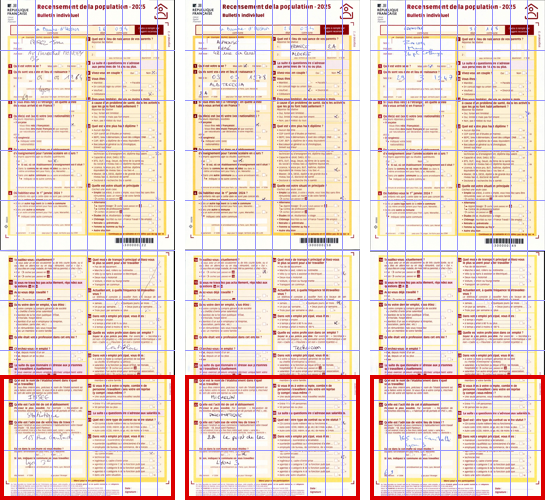

(La cellule 6b verifiera gratuitement, avec gemma4, que cette image montre bien l'adresse du Fiqual.)
Le cadre rouge = BANDE. Il doit contenir toute l'adresse manuscrite. Sinon : lire les fractions sur le quadrillage, les ecrire dans BANDE en cellule 1, et relancer depuis la cellule 1.


In [6]:
# 4. LES IMAGES DE L'ADRESSE, et l'IMAGE DE REPERAGE : le cadre rouge doit contenir l'adresse manuscrite
#    Quel type d'image porte l'adresse ? On ne suppose rien : pour chaque suffixe d'image (ADR, FL, BI...),
#    on compte combien de lignes « adresse » du Fiqual ont une image avec la meme cle, et on prend le plus frequent.
if "CAMPAGNE" not in globals() or not CAMPAGNE or "DIV" not in globals():
    raise RuntimeError("La cellule 2 (divergences) n'a pas ete lancee : c'est elle qui choisit la campagne (RG25/RG26). "
                       "Lancer les cellules DANS L'ORDRE depuis le haut (menu Run > Run All Above Selected Cell).")
IMAGES = [f for f in fs.find(f"{BUCKET}/data/raw/{CAMPAGNE}") if f.lower().endswith((".jpg", ".jpeg", ".png", ".tif", ".tiff"))]
IM = pd.DataFrame({"chemin": IMAGES})
IM["morceaux"] = IM.chemin.map(lambda c: Path(c).stem.split("_"))
IM["suffixe"] = IM.morceaux.map(lambda m: m[-1].upper() if m and not m[-1].isdigit() else "")
IM["cle"] = IM.morceaux.map(lambda m: "_".join(morceaux_utiles(m)[-2:]))


def sz(v):
    """Un identifiant sans zeros devant (0000138 = 138)."""
    v = str(v).strip()
    return v.lstrip("0") or "0" if v.isdigit() else v


# --- Rattacher chaque image a SA ligne du Fiqual, sans supposer quelles colonnes portent l'identifiant :
#     le nom d'image commence par deux identifiants (ex. 6901_5100000138_ADR : lot/UT et numero du document).
#     Une ligne du Fiqual est rattachee a une image si ces DEUX identifiants figurent dans la ligne, dans
#     n'importe quelles colonnes. Les feuilles logement et les bulletins individuels ont des numeros differents :
#     ce rattachement trouve les deux, la ou la cle « colonnes 2 et 4 » ne trouvait que l'un.
IM["id1"] = IM.morceaux.map(lambda m: sz(m[0]) if len(m) > 2 else "")
IM["id2"] = IM.morceaux.map(lambda m: sz(m[1]) if len(m) > 2 else "")
PAR_ID2 = {}
for i1, i2, s_, c_ in zip(IM.id1, IM.id2, IM.suffixe, IM.chemin):
    if i1 and i2:
        PAR_ID2.setdefault(i2, {}).setdefault(i1, []).append((s_, c_))
CHEMINS_TOUS = {}                   # (type d'image, cle de la ligne du Fiqual) -> TOUTES ses images, triees par nom
COLONNES_LIEN = Counter()           # quelles colonnes du Fiqual portent l'identifiant des images (pour information)
for (t, cle), c in LIGNE.items():
    if t not in TYPES_ADR:
        continue
    vals = [sz(x) for x in c]
    ens = set(vals)
    for j, v in enumerate(vals):
        for i1, imgs in PAR_ID2.get(v, {}).items():
            if i1 in ens:
                COLONNES_LIEN[(vals.index(i1), j)] += 1
                for s_, c_ in imgs:
                    CHEMINS_TOUS.setdefault((s_, cle), []).append(c_)
for k_ in CHEMINS_TOUS:
    CHEMINS_TOUS[k_] = sorted(set(CHEMINS_TOUS[k_]))
if not CHEMINS_TOUS:                # repli : l'ancienne cle (fin du nom de fichier)
    for s_, k_, c_ in sorted(zip(IM.suffixe, IM.cle, IM.chemin)):
        CHEMINS_TOUS.setdefault((s_, k_), []).append(c_)
print("Colonnes du Fiqual qui portent les identifiants des images (lot, document) : "
      + (", ".join(f"{a_} et {b_} ({n_} lignes)" for (a_, b_), n_ in COLONNES_LIEN.most_common(3)) or "aucune"))

cles_f = {cle for (t, cle) in LIGNE if t in TYPES_ADR}
par_suffixe = (pd.Series([s_ for (s_, k_) in CHEMINS_TOUS if k_ in cles_f]).value_counts()
               if CHEMINS_TOUS else pd.Series(dtype=int))
print(f"lignes « adresse » du Fiqual ({len(cles_f)}) qui ont une image, par type d'image : {par_suffixe.to_dict() or 'aucune'}")
if not len(par_suffixe):
    raise RuntimeError("Aucune image ne correspond aux lignes d'adresse du Fiqual (voir les types d'images ci-dessus).")
# Les vignettes d'une feuille logement portent leur role dans leur nom : ADR (localisation du logement = l'adresse),
# IDE (identifiant, occupant principal), LOG (caracteristiques), TABA a TABD (tableaux des habitants).
# On prend donc ADR quand il existe ; sinon le type le plus frequent. La cellule 6b le verifie de toute facon.
VOULU = "ADR" if CIBLE == "logement" else "BI"     # lieu de travail : sur le bulletin individuel
DOC_AUTO = VOULU if VOULU in par_suffixe.index else par_suffixe.index[0]
DOC = TYPE_IMAGE.upper() if TYPE_IMAGE else DOC_AUTO
if DOC not in par_suffixe.index:
    raise RuntimeError(f"TYPE_IMAGE = {TYPE_IMAGE!r} : aucune image de ce type pour les lignes d'adresse. "
                       f"Types disponibles : {list(par_suffixe.index)}")
POS = 0                             # rang de l'image quand un document en a plusieurs (choisi en cellule 6b)


def image_id(doc, pos):
    return doc if pos == 0 else f"{doc}-{pos + 1}"


def a_une_adresse(cle):
    """Le Fiqual contient-il une adresse (type ou nom de voie) pour ce document ? (aucune valeur affichee)"""
    t = next((t for t in TYPES_ADR if (t, cle) in LIGNE), None)
    if t is None:
        return False
    c = LIGNE[(t, cle)]
    return any(len(c) > i and normaliser(c[i]) for i in ADR_COLS[t] if ROLES[(t, i)] in ("TYPE_VOIE", "NOM_VOIE"))


def construire_app():
    """Les documents a lire : une ligne d'adresse du Fiqual + son image (type DOC, rang POS).
    En TEST_RAPIDE : 8 documents AVEC une adresse dans le Fiqual et 2 sans (sinon le test ne mesure presque rien)."""
    global APP, IMAGE_ID
    IMAGE_ID = image_id(DOC, POS)
    A_ = pd.DataFrame([{"cle": cle, "type": t, "chemin": (CHEMINS_TOUS.get((DOC, cle)) or [None] * (POS + 1))[POS]
                        if len(CHEMINS_TOUS.get((DOC, cle), [])) > POS else None}
                       for (t, cle) in LIGNE if t in TYPES_ADR]).drop_duplicates("cle")
    sans_ = int(A_.chemin.isna().sum())
    A_ = A_[A_.chemin.notna()].sort_values("cle").reset_index(drop=True)
    A_["avec_adresse"] = A_.cle.map(a_une_adresse)
    if TEST_RAPIDE:
        APP = (pd.concat([A_[A_.avec_adresse].head(8), A_[~A_.avec_adresse].head(2)])
               .sort_values("cle").reset_index(drop=True))
    else:
        APP = A_
    print(f"   documents avec une adresse dans le Fiqual : {int(A_.avec_adresse.sum())}/{len(A_)} "
          f"(les autres servent a verifier que les lecteurs repondent « vide », cellule 11 bis)")
    plusieurs_ = pd.Series({k: len(v) for (s_, k), v in CHEMINS_TOUS.items() if s_ == DOC and k in set(A_.cle)})
    print(f"-> images « {DOC} », rang {POS + 1} | {len(APP)} documents apparies au Fiqual ({sans_} lignes sans image)")
    print(f"   images « {DOC} » par document : {plusieurs_.value_counts().sort_index().to_dict()} "
          f"(nombre d'images -> nombre de documents)")
    if (plusieurs_ > 1).any():
        print(f"   {int((plusieurs_ > 1).sum())} documents ont PLUSIEURS images « {DOC} » (ex. vignettes) : "
              f"la cellule 6b verifie GRATUITEMENT laquelle montre l'adresse du Fiqual.")


construire_app()


import threading
_VERROUS_IMAGES = {}
_VERROU_GLOBAL = threading.Lock()


def image_de(doc, pos, cle):
    """Une image (type doc, rang pos) recadree selon BANDE. Sure quand plusieurs modeles la demandent EN MEME
    TEMPS : un seul la fabrique, ecriture atomique, et un fichier abime (coupure precedente) est refait."""
    f = CACHE / f"{CAMPAGNE}_{image_id(doc, pos)}_{cle}_{'_'.join(str(x) for x in BANDE)}.png"
    with _VERROU_GLOBAL:
        verrou = _VERROUS_IMAGES.setdefault((doc, pos, cle), threading.Lock())
    with verrou:
        if f.exists():
            try:
                im = Image.open(f)
                im.load()
                return im
            except OSError:
                f.unlink(missing_ok=True)           # fichier tronque : on le refait
        with fs.open(CHEMINS_TOUS[(doc, cle)][pos], "rb") as s:
            p = Image.open(io.BytesIO(s.read())).convert("RGB")
        x, y, w, h = BANDE
        L, H = p.size
        p = p.crop((int(x * L), int(y * H), int((x + w) * L), int((y + h) * H)))
        r = RESOLUTION_MAX / max(p.size)
        if r < 1:
            p = p.resize((int(p.width * r), int(p.height * r)))
        tmp = f.with_suffix(f".{threading.get_ident()}.tmp")
        p.save(tmp, format="PNG")
        os.replace(tmp, f)
        return p


def image_adresse(cle):
    """L'image lue par TOUS les modeles (type DOC, rang POS, choisis en cellules 4 et 6b)."""
    return image_de(DOC, POS, cle)


def reperage(n=3):
    """Trois images cote a cote, quadrillage tous les 10 %, le cadre BANDE en rouge."""
    pages = []
    for cle in (list(APP[APP.avec_adresse].cle) + list(APP[~APP.avec_adresse].cle))[:n]:
        with fs.open(CHEMINS_TOUS[(DOC, cle)][POS], "rb") as s:
            p = Image.open(io.BytesIO(s.read())).convert("RGB")
        r = 500 / p.height
        p = p.resize((max(1, int(p.width * r)), 500))
        dr = ImageDraw.Draw(p)
        for k in range(1, 10):
            dr.line([(0, p.height * k / 10), (p.width, p.height * k / 10)], fill=(150, 150, 255), width=1)
            dr.line([(p.width * k / 10, 0), (p.width * k / 10, p.height)], fill=(150, 150, 255), width=1)
        x, y, w, h = BANDE
        dr.rectangle([x * p.width, y * p.height, (x + w) * p.width - 1, (y + h) * p.height - 1], outline=(220, 0, 0), width=4)
        pages.append(p)
    if not pages:
        return None
    planche = Image.new("RGB", (sum(p.width for p in pages) + 10 * (len(pages) - 1), 500), "white")
    x0 = 0
    for p in pages:
        planche.paste(p, (x0, 0))
        x0 += p.width + 10
    f = ILLUS / f"reperage_adresse_{CAMPAGNE}_{IMAGE_ID}.png"
    planche.save(f)
    return f


f_rep = reperage()
if f_rep:
    print(f"Image de reperage : {f_rep} (hors Git : vraies images)")
    display(Image.open(f_rep))
print("(La cellule 6b verifiera gratuitement, avec gemma4, que cette image montre bien l'adresse du Fiqual.)")
print("Le cadre rouge = BANDE. Il doit contenir toute l'adresse manuscrite. Sinon : lire les fractions sur le "
      "quadrillage, les ecrire dans BANDE en cellule 1, et relancer depuis la cellule 1.")

In [11]:
# 5. CLES (jamais affichees ni ecrites dans le notebook)
if not os.environ.get("OPENAI_API_KEY"):
    os.environ["OPENAI_API_KEY"] = (lire_vault("onyxia-kv/farisazibert/LLM").get("OPENAI_API_KEY")
                                    or getpass.getpass("cle du service LLM du SSP Cloud : ").strip())
if not os.environ.get("EDENAI_API_KEY"):
    os.environ["EDENAI_API_KEY"] = (lire_vault("onyxia-kv/farisazibert/EDENAI").get("EDENAI_API_KEY")
                                    or getpass.getpass("cle Eden AI : ").strip())
if os.environ.get("EDENAI_API_KEY", "").startswith("hvs."):
    os.environ.pop("EDENAI_API_KEY")
    raise RuntimeError("La valeur saisie est un jeton VAULT (hvs.…), pas la cle Eden AI. "
                       "Copier la cle depuis Eden AI > Manage keys, puis relancer cette cellule.")
print("cle SSP Cloud :", "presente" if os.environ.get("OPENAI_API_KEY") else "ABSENTE")
print("cle Eden AI   :", "presente" if os.environ.get("EDENAI_API_KEY") else "ABSENTE")

cle Eden AI :  ········


cle SSP Cloud : presente
cle Eden AI   : presente


In [12]:
# 6. LA LECTURE COMMUNE : meme image (l'adresse), meme consigne, temperature 0, pour gemma4 comme pour Eden AI.
#    - parallele (N_PARALLELE appels a la fois), progression toutes les 30 s ;
#    - cache : chaque lecture reussie est gardee -> relancer ne refacture jamais ;
#    - temps, jetons et cout gardes dans le cache ;
#    - modeles « qui reflechissent » : s'ils refusent temperature ou max_tokens, on s'adapte automatiquement ;
#    - plafond : au-dela de PLAFOND_DOLLARS (cout renvoye par Eden AI), on arrete proprement.
VERSIONS = {}          # modele demande -> version reellement servie
ADAPTATIONS = {}       # modele -> parametres retires parce que refuses (note de methode)
COUT_TOTAL = 0.0
SECONDES_VUES = {}     # modele -> secondes moyennes par appel deja observees (pour estimer les durees)


def appel(modele, image, consigne, cles_json, eden=True, delai=180, tentatives=2):
    """Renvoie ({champ: texte}, reussi, infos). infos : secondes, json_ok, jetons, cout (si fournis)."""
    t = io.BytesIO()
    image.convert("RGB").save(t, format="PNG")
    b64 = base64.b64encode(t.getvalue()).decode()
    url = URL_EDEN if eden else URL_SSP
    cle_api = os.environ["EDENAI_API_KEY"] if eden else os.environ["OPENAI_API_KEY"]
    entetes = {"Authorization": f"Bearer {cle_api}", "Content-Type": "application/json"}
    if eden:
        entetes["x-edenai-metadata"] = "enabled"
    corps = {"model": modele, "stream": False, "temperature": 0, "max_tokens": MAX_JETONS,
             "messages": [{"role": "user", "content": [
                 {"type": "image_url", "image_url": {"url": f"data:image/png;base64,{b64}"}},
                 {"type": "text", "text": consigne}]}]}
    for p_ in ADAPTATIONS.get(modele, []):
        corps.pop(p_, None)
        if p_ == "max_tokens":
            corps["max_completion_tokens"] = MAX_JETONS
    erreur, essai = "", 0
    while essai < tentatives:
        t0 = time.time()
        try:
            r = requests.post(url, headers=entetes, json=corps, timeout=delai)
            texte_err = (getattr(r, "text", "") or "").lower() if getattr(r, "status_code", 200) == 400 else ""
            if texte_err and ("temperature" in texte_err or "max_tokens" in texte_err):
                retire = "temperature" if "temperature" in texte_err and "temperature" in corps else "max_tokens"
                if retire in corps:
                    corps.pop(retire)
                    if retire == "max_tokens":
                        corps["max_completion_tokens"] = MAX_JETONS
                    ADAPTATIONS.setdefault(modele, []).append(retire)
                    print(f"  [{modele}] parametre '{retire}' refuse par le modele : retire (note dans MLflow)")
                    continue
            r.raise_for_status()
            rep = r.json()
            texte = rep["choices"][0]["message"]["content"] or ""
            m = re.search(r"\{.*\}", texte, re.S)
            try:
                d = json.loads(m.group(0)) if m else {}
            except json.JSONDecodeError:
                d = {}
            VERSIONS[modele] = rep.get("model", modele)
            usage = rep.get("usage", {}) or {}
            infos = {"secondes": time.time() - t0, "json_ok": bool(d) and all(c in d for c in cles_json),
                     "jetons": usage.get("total_tokens"), "cout": rep.get("cost", usage.get("cost"))}
            return {c: str(d.get(c, "") or "") for c in cles_json}, True, infos
        except Exception as e:
            reponse = getattr(e, "response", None)
            erreur = (f"{type(e).__name__} {getattr(reponse, 'status_code', '')} "
                      f"{(getattr(reponse, 'text', '') or '')[:200]}")
            essai += 1
            time.sleep(20 * essai if getattr(reponse, "status_code", None) == 429 else 3 * essai)
    return {c: "" for c in cles_json}, False, {"erreur": erreur}


def nom_fichier(texte):
    return re.sub(r"[^a-z0-9]+", "_", texte.lower()).strip("_")


def nom_lecteur(modele, consigne=None):
    return f"{modele} · {consigne}" if consigne else modele


def chemin_cache(modele, consigne):
    """UN SEUL fichier par modele, consigne, TYPE D'IMAGE et BANDE, commun au test rapide et au complet : rien n'est
    jamais relu. Le type d'image est dans le nom : changer TYPE_IMAGE ne reprend JAMAIS des lectures faites
    sur d'autres images. (Les fichiers d'avant, sans type d'image dans le nom, ont ete lus sur une MAUVAISE image : jamais repris.)"""
    bande_ = "b" + "_".join(str(x) for x in BANDE)            # la decoupe aussi : changer BANDE = nouvelles lectures
    return RESULTATS / f"adresse_{nom_fichier(modele)}_{consigne}_{CAMPAGNE}_{IMAGE_ID}_{CIBLE_CODE}_{bande_}.csv"


def lire_cache(cache):
    L_ = pd.read_csv(cache, dtype=str, keep_default_na=False) if cache.exists() \
        else pd.DataFrame(columns=["cle", "NUMERO", "VOIE", "COMPLEMENT", "brut"])
    ancien = cache.with_name(cache.stem + "_rapide.csv")          # lectures d'un test rapide d'une version precedente
    if ancien.exists():
        A_ = pd.read_csv(ancien, dtype=str, keep_default_na=False)
        L_ = pd.concat([L_, A_[~A_.cle.isin(set(L_.cle))]], ignore_index=True)
        L_.to_csv(cache, index=False)
        ancien.rename(ancien.with_suffix(".fusionne"))
    return L_


def lectures(modele, consigne, eden=True, cles=None):
    """Lectures de tous les documents par un modele et une consigne ; cache CSV.
    Renvoie une ligne par document : cle, NUMERO, VOIE, COMPLEMENT (ramenes a 3 morceaux), brut, secondes, jetons, cout."""
    global COUT_TOTAL
    cles = list(APP.cle) if cles is None else cles
    nom = nom_lecteur(modele, consigne)
    cache = chemin_cache(modele, consigne)
    L_ = lire_cache(cache)
    faire = [c for c in cles if c not in set(L_.cle)]
    print(f"{nom} : {len(cles) - len(faire)} deja lus, {len(faire)} a lire", flush=True)
    if faire and eden and COUT_TOTAL > PLAFOND_DOLLARS:
        print(f"  PLAFOND atteint ({COUT_TOTAL:.2f} $ > {PLAFOND_DOLLARS} $) : lecture non lancee")
        return L_[L_.cle.isin(set(cles))]
    n_par = N_PARALLELE_EDEN if eden else N_PARALLELE
    sec = pd.to_numeric(L_["secondes"], errors="coerce").dropna() if "secondes" in L_ else pd.Series(dtype=float)
    moy = sec.mean() if len(sec) else SECONDES_VUES.get(modele)
    if faire:
        estim = (f"~{len(faire) * moy / n_par / 60:.0f} min ({moy:.0f} s par appel, {n_par} a la fois)"
                 if moy is not None and moy == moy else "inconnue (pas encore de lecture)")
        print(f"  duree estimee : {estim} | arret automatique au-dela de {DUREE_MAX_MINUTES} min "
              f"(ce qui est lu est garde)", flush=True)
    rows, echecs, temps, k = [], [], [], 0
    t_debut = dernier = time.time()

    stop = threading.Event()        # leve a l'interruption : les appels pas encore partis ne partent pas

    def une(cle):
        if stop.is_set():
            return cle, {}, False, {"erreur": "arrete"}
        try:
            res, ok, infos = appel(modele, image_adresse(cle), CONSIGNES[consigne], CLES_JSON[consigne], eden=eden)
        except Exception as e:      # ex. image abimee : compte comme un echec, n'arrete pas tout
            res, ok, infos = {}, False, {"erreur": f"{type(e).__name__} : {str(e)[:150]}"}
        return cle, res, ok, infos

    arret = ""
    ex = ThreadPoolExecutor(n_par)
    en_cours = {ex.submit(une, c) for c in faire}
    try:
        while en_cours:
            finis, en_cours = wait(en_cours, timeout=30, return_when=FIRST_COMPLETED)
            for f in finis:
                k += 1
                cle, res, ok, infos = f.result()
                if ok:
                    rows.append({"cle": cle, **en_trois(res, consigne),
                                 "brut": " | ".join(f"{k}={v}" for k, v in res.items()),
                                 "secondes": round(infos["secondes"], 2), "jetons": infos["jetons"],
                                 "cout": infos["cout"]})
                    temps.append(infos["secondes"])
                    if eden and isinstance(infos.get("cout"), (int, float)):
                        COUT_TOTAL += infos["cout"]
                else:
                    echecs.append((cle, infos.get("erreur", "")))
            if not arret:
                if eden and COUT_TOTAL > PLAFOND_DOLLARS:
                    arret = f"PLAFOND de depense atteint ({COUT_TOTAL:.2f} $ > {PLAFOND_DOLLARS} $)"
                elif k >= 5 and len(echecs) == k:
                    arret = "les 5 premiers appels ont tous echoue (nom du modele, cle, ou service indisponible)"
                elif k >= 20 and len(echecs) > k / 2:
                    arret = f"plus de la moitie des appels echouent ({len(echecs)}/{k})"
                elif (time.time() - t_debut) / 60 > DUREE_MAX_MINUTES:
                    arret = f"duree maximale atteinte ({DUREE_MAX_MINUTES} min)"
                if arret and en_cours:
                    stop.set()
                    for f in en_cours:
                        f.cancel()
                    en_cours = {f for f in en_cours if not f.cancelled()}
                    print(f"  ARRET de {nom} : {arret}. Ce qui est lu est garde ; relancer la cellule reprend "
                          f"la ou on s'est arrete.", flush=True)
            if len(rows) >= 10 or not en_cours:
                L_ = pd.concat([L_, pd.DataFrame(rows)], ignore_index=True)
                L_.to_csv(cache, index=False)
                rows = []
            if time.time() - dernier >= 30 or not en_cours:
                dernier = time.time()
                ecoule = time.time() - t_debut
                vitesse = f"{sum(temps[-20:]) / len(temps[-20:]):.1f} s/appel" if temps else "aucune reponse encore"
                print(f"  {nom} : {k}/{len(faire)} | {ecoule / 60:.1f} min | {vitesse} | echecs {len(echecs)} "
                      f"| cout cumule {COUT_TOTAL:.2f} $", flush=True)
    finally:
        if rows:
            L_ = pd.concat([L_, pd.DataFrame(rows)], ignore_index=True)
            L_.to_csv(cache, index=False)
        stop.set()
        ex.shutdown(wait=False, cancel_futures=True)   # bouton carre : le notebook s'arrete tout de suite
    if temps:
        SECONDES_VUES[modele] = sum(temps) / len(temps)
    if echecs:
        print(f"  {len(echecs)} echecs (relancer la cellule pour les retenter). Premier : {echecs[0][1][:200]}")
    return L_[L_.cle.isin(set(cles))].drop_duplicates("cle")


def bilan_lectures():
    """Dit clairement si tout est lu, ou ce qu'il faut relancer (relancer ne repaie rien)."""
    incomplets = {n_: d.cle.nunique() for n_, d in LECT.items() if d.cle.nunique() < len(APP)}
    if not incomplets:
        print(f"\nCOMPLET : {len(LECT)} lecteurs, {len(APP)} documents chacun.")
    else:
        print("\nINCOMPLET (arret, echecs ou plafond) : relancer CETTE cellule, elle reprend la ou elle s'est arretee :")
        for n_, k_ in incomplets.items():
            print(f"  - {n_} : {k_}/{len(APP)}")


print("outils de lecture prets")

outils de lecture prets


In [13]:
# 6b. CONTROLE GRATUIT, AVANT TOUTE DEPENSE : l'image lue montre-t-elle VRAIMENT l'adresse du Fiqual ?
#     gemma4 (interne, gratuit) lit quelques documents sur CHAQUE image possible (chaque type, et chaque rang
#     quand un document a plusieurs images). On compare au PMQ (numero + voie) et on garde l'image qui lui
#     ressemble le plus. Si AUCUNE ne ressemble a l'adresse du Fiqual, on S'ARRETE ici : pas un centime depense.
#     Resultats gardes en cache, PAR BANDE : changer BANDE refait le controle, relancer sans rien changer ne refait rien.
N_CONTROLE = 8                      # documents par image candidate
SEUIL_CONTROLE = 0.6                # ressemblance moyenne minimale (1 = identique) pour accepter une image
RANGS_MAX = 8                       # au plus 8 images par document examinees


def sans_zeros_(v):
    return re.sub(r"\b0+(?=\d)", "", v)


def adresse_pmq(cle):
    """numero + voie du PMQ (sans complement), normalises, sans espaces."""
    t = next((t for t in TYPES_ADR if (t, cle) in LIGNE), None)
    if t is None:
        return ""
    c = LIGNE[(t, cle)]
    v = " ".join(c[i] for i in ADR_COLS[t] if ROLES[(t, i)] != "COMPLEMENT" and len(c) > i)
    return compact(sans_zeros_(norm_adresse(v)))


def ressemblance(a, b):
    if not a or not b:
        return 0.0
    return max(0.0, 1 - distance(a, b) / max(len(a), len(b)))


etiquette_bande = "_".join(str(x) for x in BANDE)
f_ctrl = RESULTATS / f"controle_image_{CAMPAGNE}_{CIBLE_CODE}_bande_{etiquette_bande}_r{RESOLUTION_MAX}.json"
CTRL = json.loads(f_ctrl.read_text()) if f_ctrl.exists() else {}
print(f"BANDE = {BANDE} | cache du controle : {f_ctrl.name} ({len(CTRL)} lectures deja faites)")

types_cand = [TYPE_IMAGE.upper()] if TYPE_IMAGE else \
    ([DOC_AUTO] + [d_ for d_ in par_suffixe.index if d_ != DOC_AUTO])[:5]
if CIBLE == "travail":                    # l'adresse du lieu de travail n'est que sur le bulletin individuel
    types_cand = [d_ for d_ in types_cand if d_ == "BI"] or types_cand
candidats = []
for d_ in types_cand:
    n_max = max((len(v) for (s_, k), v in CHEMINS_TOUS.items() if s_ == d_ and k in cles_f), default=0)
    candidats += [(d_, p_) for p_ in range(min(n_max, RANGS_MAX))]
print(f"Images candidates : {len(candidats)} ({', '.join(image_id(d_, p_) for d_, p_ in candidats)}) | "
      f"{N_CONTROLE} documents chacune, lus par gemma4 (gratuit)", flush=True)

taches = []
for d_, p_ in candidats:
    cles_c = [k for k in sorted(cles_f) if len(CHEMINS_TOUS.get((d_, k), [])) > p_ and adresse_pmq(k)][:N_CONTROLE]
    taches += [(d_, p_, k) for k in cles_c if f"{image_id(d_, p_)}|{k}" not in CTRL]


def controler(tache):
    d_, p_, k = tache
    try:
        res, ok, _ = appel(MODELE_GEMMA, image_de(d_, p_, k), CONSIGNES["V1"], CLES_JSON["V1"], eden=False)
    except Exception:
        return tache, None
    if not ok:
        return tache, None
    a = en_trois(res, "V1")
    return tache, compact(sans_zeros_(norm_adresse(f"{a['NUMERO']} {a['VOIE']}")))


if taches:
    ex = ThreadPoolExecutor(N_PARALLELE)
    try:
        for i_, (tache, lu) in enumerate(ex.map(controler, taches), 1):
            d_, p_, k = tache
            if lu is not None:                     # un appel en echec n'est pas garde : il sera retente
                CTRL[f"{image_id(d_, p_)}|{k}"] = round(ressemblance(adresse_pmq(k), lu), 3)
            if i_ % 10 == 0 or i_ == len(taches):
                print(f"  {i_}/{len(taches)} lectures de controle", flush=True)
                f_ctrl.write_text(json.dumps(CTRL))
    finally:
        ex.shutdown(wait=False, cancel_futures=True)
        f_ctrl.write_text(json.dumps(CTRL))

lignes_c = []
for d_, p_ in candidats:
    sc = [v for kk, v in CTRL.items() if kk.split("|")[0] == image_id(d_, p_)]
    if sc:
        lignes_c.append({"image": image_id(d_, p_), "type": d_, "rang": p_ + 1, "documents": len(sc),
                         "ressemblance_moyenne": round(sum(sc) / len(sc), 2),
                         "presque_identiques_%": round(sum(x >= 0.8 for x in sc) / len(sc) * 100)})
CONTROLE = pd.DataFrame(lignes_c).sort_values("ressemblance_moyenne", ascending=False).reset_index(drop=True) \
    if lignes_c else pd.DataFrame()
print("\nRessemblance entre la lecture de gemma4 et l'adresse du PMQ (numero + voie), par image candidate :")
display(CONTROLE)
if not len(CONTROLE):
    raise RuntimeError("Controle impossible (gemma4 n'a rien lu) : verifier qu'il repond (commande curl) "
                       "et la cle SSP Cloud (cellule 5), puis relancer cette cellule.")
meilleure = CONTROLE.iloc[0]
if meilleure.ressemblance_moyenne < SEUIL_CONTROLE:
    conseil = ("Pour le LIEU DE TRAVAIL : verifier que BANDE (cellule 1) entoure bien la question du lieu de travail "
               "sur l'image de reperage (cellule 4) ; la cellule 6a peut la retrouver automatiquement."
               if CIBLE == "travail" else
               "Pour le LOGEMENT : le Fiqual ne contient peut-etre pas cette adresse (au RP, seule l'adresse du lieu "
               "de travail est ressaisie) ; il faut alors une autre reference.")
    raise RuntimeError(
        f"ARRET AVANT TOUTE DEPENSE : aucune image ne montre l'adresse du Fiqual (meilleure : {meilleure.image}, "
        f"ressemblance {meilleure.ressemblance_moyenne} < {SEUIL_CONTROLE}). {conseil} Sinon : l'image et la ligne du "
        f"Fiqual ne designent pas le meme document (cle) - a voir avec Cedric.")
if (meilleure.type, int(meilleure.rang) - 1) != (DOC, POS):
    DOC, POS = meilleure.type, int(meilleure.rang) - 1
    print(f"\n-> l'image de l'adresse est « {meilleure.image} » (et non celle choisie a la cellule 4) : on la prend.")
    construire_app()
    f_rep = reperage()
else:
    print(f"\n-> l'image choisie a la cellule 4 (« {IMAGE_ID} ») est bien celle de l'adresse.")
print(f"Image retenue : {IMAGE_ID} | bande {BANDE} | ressemblance moyenne avec le PMQ {meilleure.ressemblance_moyenne} "
      f"({meilleure['presque_identiques_%']} % presque identiques). Les lectures sont rangees sous ce nom d'image.")

BANDE = (0.0, 0.75, 1.0, 0.25) | cache du controle : controle_image_RG25_LT_bande_0.0_0.75_1.0_0.25_r2400.json (8 lectures deja faites)
Images candidates : 1 (BI) | 8 documents chacune, lus par gemma4 (gratuit)

Ressemblance entre la lecture de gemma4 et l'adresse du PMQ (numero + voie), par image candidate :


,image,type,rang,documents,ressemblance_moyenne,presque_identiques_%
0,BI,BI,1,8,0.76,62



-> l'image choisie a la cellule 4 (« BI ») est bien celle de l'adresse.
Image retenue : BI | bande (0.0, 0.75, 1.0, 0.25) | ressemblance moyenne avec le PMQ 0.76 (62 % presque identiques). Les lectures sont rangees sous ce nom d'image.


In [14]:
# 6a. RECHERCHE AUTOMATIQUE DE LA BANDE (gratuite : gemma4) : ou est ecrite l'adresse du lieu de travail ?
#     Le bulletin est decoupe en bandes horizontales qui se chevauchent ; gemma4 lit l'adresse sur chacune, pour
#     quelques documents qui en ont une ; on garde la bande qui ressemble le plus au PMQ (numero + voie).
#     Resultats gardes en cache : relancer ne refait que les lectures manquantes.
HAUTEUR_BANDE, PAS_BANDE = 0.25, 0.125       # bandes d'un quart de page, tous les huitiemes
N_DOCS_BANDE = 6
BANDES_TESTEES = [(0.0, round(i * PAS_BANDE, 3), 1.0, HAUTEUR_BANDE)
                  for i in range(int(round((1 - HAUTEUR_BANDE) / PAS_BANDE)) + 1)]


def adresse_pmq_(cle):
    """numero + voie du PMQ (sans complement), normalises, sans espaces."""
    t = next((t for t in TYPES_ADR if (t, cle) in LIGNE), None)
    if t is None:
        return ""
    c = LIGNE[(t, cle)]
    v = " ".join(c[i] for i in ADR_COLS[t] if ROLES[(t, i)] != "COMPLEMENT" and len(c) > i)
    return compact(re.sub(r"\b0+(?=\d)", "", norm_adresse(v)))


def ressemblance_(a, b):
    return max(0.0, 1 - distance(a, b) / max(len(a), len(b))) if a and b else 0.0


def decoupe(cle, bande):
    """La bande de l'image du document, reduite si besoin a RESOLUTION_MAX."""
    with fs.open(CHEMINS_TOUS[(DOC, cle)][POS], "rb") as s:
        p = Image.open(io.BytesIO(s.read())).convert("RGB")
    x, y, w, h = bande
    L, H = p.size
    p = p.crop((int(x * L), int(y * H), int((x + w) * L), int((y + h) * H)))
    r = RESOLUTION_MAX / max(p.size)
    return p.resize((int(p.width * r), int(p.height * r))) if r < 1 else p


docs_b = [k for k in APP.cle if adresse_pmq_(k) and (DOC, k) in CHEMINS_TOUS][:N_DOCS_BANDE]
if len(docs_b) < N_DOCS_BANDE:
    docs_b += [k for k in sorted(cles_f) if k not in docs_b and adresse_pmq_(k)
               and (DOC, k) in CHEMINS_TOUS][:N_DOCS_BANDE - len(docs_b)]
if not docs_b:
    raise RuntimeError(f"aucun document avec une adresse et une image « {DOC} » : verifier les cellules 3 et 4")

f_bandes = RESULTATS / f"recherche_bande_{CAMPAGNE}_{image_id(DOC, POS)}_{CIBLE_CODE}.json"
SCORES_B = json.loads(f_bandes.read_text()) if f_bandes.exists() else {}
taches_b = [(b, c) for b in BANDES_TESTEES for c in docs_b if f"{b}|{c}" not in SCORES_B]
print(f"{len(BANDES_TESTEES)} bandes x {len(docs_b)} documents : {len(BANDES_TESTEES) * len(docs_b) - len(taches_b)} "
      f"deja lues (cache), {len(taches_b)} lectures gemma4 a faire (gratuites)", flush=True)


def lire_bande(tache):
    bande, cle = tache
    try:
        res, ok, _ = appel(MODELE_GEMMA, decoupe(cle, bande), CONSIGNES["V1"], CLES_JSON["V1"], eden=False)
    except Exception:
        return tache, None
    if not ok:
        return tache, None
    a = en_trois(res, "V1")
    lu = compact(re.sub(r"\b0+(?=\d)", "", norm_adresse(f"{a['NUMERO']} {a['VOIE']}")))
    return tache, ressemblance_(adresse_pmq_(cle), lu)


if taches_b:
    ex = ThreadPoolExecutor(N_PARALLELE)
    try:
        for k_, ((bande, cle), s_) in enumerate(ex.map(lire_bande, taches_b), 1):
            if s_ is not None:                       # un appel en echec n'est pas garde : il sera retente
                SCORES_B[f"{bande}|{cle}"] = round(s_, 3)
            if k_ % 10 == 0 or k_ == len(taches_b):
                print(f"  {k_}/{len(taches_b)} lectures", flush=True)
                f_bandes.write_text(json.dumps(SCORES_B))
    finally:
        ex.shutdown(wait=False, cancel_futures=True)
        f_bandes.write_text(json.dumps(SCORES_B))

lignes_b = []
for b in BANDES_TESTEES:
    v = [SCORES_B[f"{b}|{c}"] for c in docs_b if f"{b}|{c}" in SCORES_B]
    if v:
        lignes_b.append({"bande (gauche, haut, largeur, hauteur)": b, "haut_%": int(round(b[1] * 100)),
                         "bas_%": int(round((b[1] + b[3]) * 100)), "documents": len(v),
                         "ressemblance_moyenne": round(sum(v) / len(v), 2),
                         "presque_identiques": sum(x >= 0.8 for x in v)})
if not lignes_b:
    raise RuntimeError("gemma4 n'a rien lu : verifier qu'il repond (commande curl), puis relancer cette cellule")
RECHERCHE_BANDE = pd.DataFrame(lignes_b).sort_values("ressemblance_moyenne", ascending=False).reset_index(drop=True)
display(RECHERCHE_BANDE)

meilleure_b = RECHERCHE_BANDE.iloc[0]
bande_b = meilleure_b["bande (gauche, haut, largeur, hauteur)"]
if meilleure_b["ressemblance_moyenne"] >= 0.6:
    print(f"\n-> l'adresse du lieu de travail est entre {meilleure_b['haut_%']} % et {meilleure_b['bas_%']} % "
          f"de la hauteur. Mettre en cellule 1 :\n   BANDE = {bande_b}\n"
          "   puis relancer depuis la cellule 1 (la cellule 6b le confirmera).")
else:
    print(f"\nAucune bande ne convient (meilleure : {meilleure_b['ressemblance_moyenne']}). L'adresse du lieu de "
          "travail n'est peut-etre pas sur CETTE image du bulletin (recto / verso) : voir le diagnostic ci-dessous.")
    par_doc = Counter(s_ for (s_, k_) in CHEMINS_TOUS if k_ in set(docs_b))
    print("types d'images disponibles pour ces documents :", dict(par_doc),
          "| images BI par document :", {k_: len(CHEMINS_TOUS.get(("BI", k_), [])) for k_ in docs_b})

7 bandes x 6 documents : 42 deja lues (cache), 0 lectures gemma4 a faire (gratuites)


,"bande (gauche, haut, largeur, hauteur)",haut_%,bas_%,documents,ressemblance_moyenne,presque_identiques
0,"(0.0, 0.75, 1.0, 0.25)",75,100,6,0.76,4
1,"(0.0, 0.0, 1.0, 0.25)",0,25,6,0.20,0
2,"(0.0, 0.625, 1.0, 0.25)",62,88,6,0.07,0
3,"(0.0, 0.25, 1.0, 0.25)",25,50,6,0.00,0
4,"(0.0, 0.125, 1.0, 0.25)",12,38,6,0.00,0
5,"(0.0, 0.5, 1.0, 0.25)",50,75,6,0.00,0
6,"(0.0, 0.375, 1.0, 0.25)",38,62,6,0.00,0



-> l'adresse du lieu de travail est entre 75 % et 100 % de la hauteur. Mettre en cellule 1 :
   BANDE = (0.0, 0.75, 1.0, 0.25)
   puis relancer depuis la cellule 1 (la cellule 6b le confirmera).


## 7. Essai : 3 documents par modèle Eden AI, avant toute dépense

Chaque modèle lit 3 adresses avec la consigne la plus exigeante (V1). On vérifie : **`json_ok`** = 1 (bon format),
**`version_servie`** (le modèle réellement utilisé), **temps, jetons, coût** (estimation du total affichée).
Un nom de modèle faux est **écarté sans rien coûter**. La cellule 9 lance ensuite automatiquement ceux qui ont réussi.

In [15]:
# 7. ESSAI sur N_ESSAI documents par modele Eden AI (consigne V1, la plus longue : si elle passe, V0 passe aussi)
#    - les modeles sont essayes EN MEME TEMPS (un fil par modele) : la cellule dure le temps du modele le plus lent,
#      pas la somme de tous ;
#    - une ligne s'affiche A CHAQUE appel, et toutes les 30 s on voit qui on attend encore : la cellule ne parait
#      jamais bloquee ;
#    - un appel qui depasse DELAI_ESSAI secondes est un echec : modele ecarte (trop lent pour 30 000 documents) ;
#    - AUCUN GASPILLAGE : chaque lecture payee est ecrite tout de suite dans le cache des lectures. Si on
#      interrompt la cellule (bouton carre) et qu'on la relance, rien n'est repaye ; et ces documents ne seront
#      pas relus a la cellule 9.
DELAI_ESSAI = 90                    # secondes maximum par appel pendant l'essai
REESSAYER_ECARTES = False           # True = retenter les modeles ecartes a un essai precedent (ex. nom corrige)
f_essai = RESULTATS / f"essai_{CAMPAGNE}.csv"
DEJA_ESSAI = pd.read_csv(f_essai) if f_essai.exists() else pd.DataFrame(columns=["modele", "cle"])
N_ESSAI_MAX = 170                    # l'essai sert a verifier qu'un modele REPOND bien, pas a mesurer : 3 a 5 suffisent
if N_ESSAI > N_ESSAI_MAX:
    print(f"N_ESSAI = {N_ESSAI} est trop grand pour un essai : ramene a {N_ESSAI_MAX} "
          f"(la lecture de tous les documents se fait a la cellule 9, avec ses garde-fous).")
    N_ESSAI = N_ESSAI_MAX
N_ESSAI = min(N_ESSAI, len(APP))
cles_essai = list(APP.cle[:N_ESSAI])
STOP_ESSAI = threading.Event()      # leve en cas d'interruption ou d'erreur : tous les fils s'arretent
cons_essai = "V1" if "V1" in CONSIGNES_TESTEES else CONSIGNES_TESTEES[0]


def ligne_essai(modele, cle, secondes, json_ok, jetons, cout):
    return {"modele": modele, "cle": cle, "categorie": CATEGORIE[modele].split(" - ")[0],
            "version_servie": VERSIONS.get(modele, "?"), "secondes": secondes, "json_ok": json_ok,
            "jetons": jetons, "cout": cout}


_ECRAN = threading.Lock()


def dire(texte):
    """Affichage depuis plusieurs fils sans que les lignes se melangent."""
    with _ECRAN:
        print(texte, flush=True)


def essayer(modele):
    """Les N_ESSAI appels d'UN modele, l'un apres l'autre ; arret au premier echec.
    Un document deja lu (cache) est repris sans appel. Renvoie (lignes, reussi, cout_nouveau)."""
    cache = chemin_cache(modele, cons_essai)
    L_ = lire_cache(cache)
    out, cout_nouveau = [], 0.0
    for i, cle in enumerate(cles_essai, 1):
        if STOP_ESSAI.is_set():                                  # interruption : on s'arrete tout de suite
            return out, False, cout_nouveau
        if cle in set(L_.cle):                                   # deja paye : repris, 0 $
            r_ = L_[L_.cle == cle].iloc[0]
            out.append(ligne_essai(modele, cle, pd.to_numeric(r_.get("secondes"), errors="coerce"),
                                   str(r_.get("json_ok", "True")) != "False",
                                   pd.to_numeric(r_.get("jetons"), errors="coerce"),
                                   pd.to_numeric(r_.get("cout"), errors="coerce")))
            dire(f"  {modele} : document {i}/{len(cles_essai)} deja lu (cache, 0 $)")
            continue
        try:
            image_ = image_adresse(cle)
        except Exception as e:                                   # probleme d'IMAGE, pas du modele : pas ecarte
            dire(f"  {modele} : image du document {i} illisible ({type(e).__name__}) - essai interrompu, "
                 f"relancer la cellule")
            return out, False, cout_nouveau
        res, ok, infos = appel(modele, image_, CONSIGNES[cons_essai], CLES_JSON[cons_essai],
                               eden=True, delai=DELAI_ESSAI, tentatives=1)
        if not ok:
            err = infos.get("erreur", "")
            raison = "TROP LENT (> {DELAI_ESSAI} s)".format(DELAI_ESSAI=DELAI_ESSAI) if "Timeout" in err else err[:200]
            dire(f"  {modele} : ECHEC au document {i}/{len(cles_essai)} - {raison}\n"
                  f"    -> modele ecarte (nom a verifier dans Eden AI > Models, ou modele trop lent)")
            ECARTES[modele] = raison
            return out, False, cout_nouveau
        cout = infos["cout"] if isinstance(infos.get("cout"), (int, float)) else None
        cout_nouveau += cout or 0.0
        L_ = pd.concat([L_, pd.DataFrame([{
            "cle": cle, **en_trois(res, cons_essai), "brut": " | ".join(f"{k}={v}" for k, v in res.items()),
            "secondes": round(infos["secondes"], 2), "jetons": infos["jetons"], "cout": cout,
            "json_ok": infos["json_ok"]}])], ignore_index=True)
        L_.to_csv(cache, index=False)                            # ecrit TOUT DE SUITE : rien ne se perd
        out.append(ligne_essai(modele, cle, infos["secondes"], infos["json_ok"], infos["jetons"], cout))
        dire(f"  {modele} : document {i}/{len(cles_essai)} lu en {infos['secondes']:.0f} s | "
              f"{'reponse au bon format' if infos['json_ok'] else 'REPONSE MAL FORMEE'} | "
              f"cout {f'{cout:.4f} $' if cout is not None else 'non fourni'}")
    return out, True, cout_nouveau


f_ecartes = RESULTATS / f"essai_ecartes_{CAMPAGNE}.json"
ECARTES = json.loads(f_ecartes.read_text()) if f_ecartes.exists() and not REESSAYER_ECARTES else {}
lignes, a_essayer = [], []
for modele in MODELES_EDEN:
    deja = DEJA_ESSAI[DEJA_ESSAI.modele == modele]
    if modele in ECARTES:
        print(f"{modele} : ecarte a un essai precedent ({ECARTES[modele][:80]}) - pas retente "
              f"(REESSAYER_ECARTES = True pour le retenter)")
    elif len(deja) >= N_ESSAI:
        lignes += deja.to_dict("records")
        VERSIONS[modele] = str(deja.version_servie.iloc[0])
        print(f"{modele} : deja essaye (resultat en cache, 0 $)")
    else:
        a_essayer.append(modele)


def sauver_essai():
    E_ = pd.DataFrame(lignes)
    if len(E_):
        pd.concat([DEJA_ESSAI[~DEJA_ESSAI.modele.isin(set(E_.modele))], E_], ignore_index=True).to_csv(f_essai, index=False)


if a_essayer:
    print(f"\nEssai de {len(a_essayer)} modeles EN MEME TEMPS, {N_ESSAI} documents chacun "
          f"(au plus {DELAI_ESSAI} s par appel, donc au plus ~{N_ESSAI * DELAI_ESSAI // 60 + 1} min) :", flush=True)
    t_debut = time.time()
    ex = ThreadPoolExecutor(len(a_essayer))
    en_cours = {ex.submit(essayer, m_): m_ for m_ in a_essayer}
    try:
        while en_cours:
            finis, _ = wait(set(en_cours), timeout=30, return_when=FIRST_COMPLETED)
            for f in finis:
                modele = en_cours.pop(f)
                out, ok, cout_ = f.result()
                COUT_TOTAL += cout_
                if ok:
                    lignes += out
                    sauver_essai()                               # garde au fil de l'eau
            if en_cours:
                dire(f"  ... {time.time() - t_debut:.0f} s : on attend encore {', '.join(en_cours.values())}")
    finally:
        STOP_ESSAI.set()                                         # interruption ou erreur : tous les fils s'arretent
        ex.shutdown(wait=False, cancel_futures=True)             # et le notebook n'est pas bloque
    f_ecartes.write_text(json.dumps(ECARTES, ensure_ascii=False, indent=1))
    print(f"Essai termine en {time.time() - t_debut:.0f} s | cout de l'essai {COUT_TOTAL:.2f} $")

ESSAI = pd.DataFrame(lignes)
sauver_essai()
if len(ESSAI):
    SECONDES_VUES.update(pd.to_numeric(ESSAI.secondes, errors="coerce").groupby(ESSAI.modele).mean().dropna().to_dict())
OK_ESSAI = (list(ESSAI.groupby("modele").json_ok.mean().loc[lambda x: x >= 0.6].index) if len(ESSAI) else [])
if len(ESSAI):
    with pd.option_context("display.width", 250):
        display(ESSAI.groupby(["categorie", "modele", "version_servie"]).agg(
            appels=("secondes", "size"), s_par_appel=("secondes", "mean"), json_ok=("json_ok", "mean"),
            jetons_par_appel=("jetons", "mean")).round(2))
    total, minutes = 0.0, 0.0
    for m_, g_ in ESSAI.groupby("modele"):
        reste = len(APP) * len(CONSIGNES_TESTEES) - sum(
            lire_cache(chemin_cache(m_, c_)).cle.isin(set(APP.cle)).sum() for c_ in CONSIGNES_TESTEES)
        couts = pd.to_numeric(g_.cout, errors="coerce").dropna()
        s_moy = pd.to_numeric(g_.secondes, errors="coerce").mean()
        m_min = max(0, reste) * s_moy / N_PARALLELE_EDEN / 60 if s_moy == s_moy else 0.0
        minutes += m_min
        total += couts.mean() * max(0, reste) if len(couts) else 0
        print(f"{m_:34s} reste {max(0, reste):4d} lectures a faire | cout estime "
              f"{f'{couts.mean() * max(0, reste):.2f} $' if len(couts) else 'inconnu'} | duree estimee ~{m_min:.0f} min"
              + (" (ATTENTION : plus long que DUREE_MAX_MINUTES, il sera arrete puis repris a la relance)"
                 if m_min / max(1, len(CONSIGNES_TESTEES)) > DUREE_MAX_MINUTES else ""))
    print(f"\nEstimation de la cellule 9 (seulement ce qui n'est pas encore lu) : ~{total:.2f} $ "
          f"(plafond {PLAFOND_DOLLARS} $) et ~{minutes:.0f} min ({N_PARALLELE_EDEN} appels a la fois)")
elif not MODELES_EDEN:
    print("Eden AI desactive (UTILISER_EDEN = False) ou aucun modele : gemma4 seul.")
print(f"\nModeles qui ont reussi l'essai : {OK_ESSAI or 'aucun'}")

google/gemini-pro-latest : deja essaye (resultat en cache, 0 $)
mistral/pixtral-large-latest : ecarte a un essai precedent (HTTPError 400 {"error":{"message":"Model(s) not found or inactive: mistral/pixtr) - pas retente (REESSAYER_ECARTES = True pour le retenter)

Essai de 5 modeles EN MEME TEMPS, 169 documents chacun (au plus 90 s par appel, donc au plus ~254 min) :
  anthropic/claude-opus-latest : document 1/169 deja lu (cache, 0 $)
  openai/gpt-latest : document 1/169 deja lu (cache, 0 $)
  qwen/qwen3-vl-plus : document 1/169 deja lu (cache, 0 $)
  google/gemini-flash-latest : document 1/169 deja lu (cache, 0 $)
  anthropic/claude-sonnet-latest : document 1/169 deja lu (cache, 0 $)
  openai/gpt-latest : document 2/169 deja lu (cache, 0 $)
  anthropic/claude-opus-latest : document 2/169 deja lu (cache, 0 $)
  qwen/qwen3-vl-plus : document 2/169 deja lu (cache, 0 $)
  google/gemini-flash-latest : document 2/169 deja lu (cache, 0 $)
  anthropic/claude-sonnet-latest : document 2/169 dej

appels  s_par_appel  json_ok  jetons_par_appel
categorie               modele                         version_servie                                                   
A. phare ferme          anthropic/claude-opus-latest   ?                      61         4.73      1.0           3479.25
                                                       claude-opus-5-5       108         4.68      1.0           3490.61
                        google/gemini-pro-latest       ?                     169        12.87      1.0           1554.45
                        openai/gpt-latest              ?                      59         5.06      1.0           2812.27
                                                       gpt-6-astra           110         5.80      1.0           2824.90
B. ouvert plus gros     qwen/qwen3-vl-plus             ?                      66         4.09      1.0           2451.08
                                                       qwen3-vl-plus         103         4.23      1.0           2451.13
C. rapide et economique anthropic/claude-sonnet-latest ?                      64         4.13      1.0           3497.23
                                                       claude-sonnet-5-5     105         3.93      1.0           3478.69
                        google/gemini-flash-latest     ?                      42         7.79      1.0           2041.74
                                                       gemini-3.8-flash      127         8.71      1.0           2049.20

anthropic/claude-opus-latest       reste  159 lectures a faire | cout estime 3.21 $ | duree estimee ~2 min
anthropic/claude-sonnet-latest     reste  159 lectures a faire | cout estime 1.60 $ | duree estimee ~1 min
google/gemini-flash-latest         reste  159 lectures a faire | cout estime 0.48 $ | duree estimee ~3 min
google/gemini-pro-latest           reste  318 lectures a faire | cout estime 1.12 $ | duree estimee ~9 min
openai/gpt-latest                  reste  159 lectures a faire | cout estime 4.89 $ | duree estimee ~2 min
qwen/qwen3-vl-plus                 reste  159 lectures a faire | cout estime 0.06 $ | duree estimee ~1 min

Estimation de la cellule 9 (seulement ce qui n'est pas encore lu) : ~11.35 $ (plafond 60.0 $) et ~17 min (8 appels a la fois)

Modeles qui ont reussi l'essai : ['anthropic/claude-opus-latest', 'anthropic/claude-sonnet-latest', 'google/gemini-flash-latest', 'google/gemini-pro-latest', 'openai/gpt-latest', 'qwen/qwen3-vl-plus']


In [18]:
# 8. GEMMA4, LA REFERENCE (gratuite, interne), avec chaque consigne.
#    Les lectures de l'ancien notebook date_naissance_adresse ne sont PAS reprises : elles ont ete faites avec
#    une bande mal placee (la bande coupait l'adresse). Tout est relu ici, sur la meme image pour tous.
LECT = {}
for cons in CONSIGNES_TESTEES:
    LECT[nom_lecteur(MODELE_GEMMA, cons)] = lectures(MODELE_GEMMA, cons, eden=False)
print({n_: f"{len(d)}/{len(APP)} documents" for n_, d in LECT.items()})
bilan_lectures()

gemma4-26b-moe · V0 : 169 deja lus, 0 a lire
gemma4-26b-moe · V1 : 169 deja lus, 0 a lire
{'gemma4-26b-moe · V0': '169/169 documents', 'gemma4-26b-moe · V1': '169/169 documents'}

COMPLET : 2 lecteurs, 169 documents chacun.


In [17]:
# 9. LES GRANDS MODELES sur tous les documents, avec chaque consigne (cache : rien n'est paye deux fois)
A_LANCER = MODELES_RETENUS or OK_ESSAI
print(f"Modeles lus sur tous les documents : {A_LANCER or 'aucun'}"
      + ("" if MODELES_RETENUS else "  (automatiquement : ceux qui ont reussi l'essai)"))
for modele in A_LANCER:
    for cons in CONSIGNES_TESTEES:
        LECT[nom_lecteur(modele, cons)] = lectures(modele, cons, eden=True)
print(f"\nCout cumule (renvoye par Eden AI) : {COUT_TOTAL:.2f} $")
print({n_: f"{len(d)}/{len(APP)} documents" for n_, d in LECT.items()})
bilan_lectures()

Modeles lus sur tous les documents : ['anthropic/claude-opus-latest', 'anthropic/claude-sonnet-latest', 'google/gemini-flash-latest', 'google/gemini-pro-latest', 'openai/gpt-latest', 'qwen/qwen3-vl-plus']  (automatiquement : ceux qui ont reussi l'essai)
anthropic/claude-opus-latest · V0 : 10 deja lus, 159 a lire
  duree estimee : ~2 min (5 s par appel, 8 a la fois) | arret automatique au-dela de 60 min (ce qui est lu est garde)
  anthropic/claude-opus-latest · V0 : 47/159 | 0.5 min | 4.1 s/appel | echecs 0 | cout cumule 7.85 $
  anthropic/claude-opus-latest · V0 : 94/159 | 1.0 min | 4.5 s/appel | echecs 0 | cout cumule 8.65 $
  anthropic/claude-opus-latest · V0 : 143/159 | 1.5 min | 4.3 s/appel | echecs 0 | cout cumule 9.48 $
  anthropic/claude-opus-latest · V0 : 159/159 | 1.7 min | 3.9 s/appel | echecs 0 | cout cumule 9.75 $
anthropic/claude-opus-latest · V1 : 169 deja lus, 0 a lire
anthropic/claude-sonnet-latest · V0 : 10 deja lus, 159 a lire
  duree estimee : ~1 min (4 s par appel, 

In [34]:
# 10. LA TABLE LIGNE PAR LIGNE : pour chaque document et chaque MORCEAU de l'adresse, PMQ, PAD, SeRN,
#     verite arbitree, et la lecture de chaque lecteur.
#     Morceaux juges : « numero » (chiffres seuls), « voie » (type + nom), « numero + voie » (LE PRINCIPAL),
#     et « adresse complete » (avec complement) si le Fiqual a une colonne de complement.
#     Comparaison : majuscules, sans accent, abreviations developpees des deux cotes (BD = BOULEVARD), sans espaces.
ORDRE_GROUPE = {"A": 0, "B": 1, "C": 2}


def valeur(cle, t, i, source):
    """(valeur, groupe) d'une colonne du Fiqual pour une source : PMQ, PAD ou ARB (verite arbitree)."""
    c = LIGNE.get((t, cle))
    pmq = c[i].strip() if c and len(c) > i else ""
    var = COLVAR.get((t, i))
    d = DIVX.get((cle, var)) if var else None
    if d is None:
        return pmq, "A"
    g = "B" if d.arbitree else "C"
    if source == "PMQ":
        return pmq, g
    if source == "PAD":
        return d.VALEUR_PAD, g
    return (d.VALEUR_ATTENDUE if d.arbitree else None), g


def reference(cle, t, source):
    """L'adresse de reference en trois parties (NUMERO avec indice, VOIE, COMPLEMENT) et le groupe de chaque partie.
    Une partie vaut None si une de ses colonnes a une divergence non arbitree (verite inconnue pour CETTE partie)."""
    parts = {"NUMERO": [], "VOIE": [], "COMPLEMENT": []}
    grp = {"NUMERO": "A", "VOIE": "A", "COMPLEMENT": "A"}
    for i in ADR_COLS[t]:
        v, g = valeur(cle, t, i, source)
        r_ = ROLES[(t, i)]
        cible = "NUMERO" if r_ in ("NUMERO", "INDICE") else "COMPLEMENT" if r_ == "COMPLEMENT" else "VOIE"
        grp[cible] = max(grp[cible], g, key=ORDRE_GROUPE.get)
        if v is None or parts[cible] is None:
            parts[cible] = None
        elif normaliser(v):
            parts[cible].append(normaliser(v))
    return {k: (None if v is None else " ".join(v)) for k, v in parts.items()}, grp


AVEC_COMPLEMENT = any(r_ == "COMPLEMENT" for r_ in ROLES.values())


def chiffres(v):
    m = re.search(r"\d+", v or "")
    return str(int(m.group(0))) if m else ""


def sans_zeros(v):
    """Les nombres sans zeros devant (le Fiqual peut stocker 0012 la ou le modele lit 12)."""
    return re.sub(r"\b0+(?=\d)", "", v)


BESOIN = {"numero": ["NUMERO"], "voie": ["VOIE"], "numero + voie": ["NUMERO", "VOIE"],
          "adresse complete": ["NUMERO", "VOIE", "COMPLEMENT"]}


def morceaux(a):
    """Les morceaux compares, a partir des trois parties. Un morceau vaut None si une de ses parties est inconnue."""
    if a is None:
        return None
    if any("ILLISIBLE" in normaliser(a.get(k) or "") for k in ("NUMERO", "VOIE", "COMPLEMENT")):
        return {c: "ILLISIBLE" for c in BESOIN}
    n_ = {k: (None if a.get(k) is None else sans_zeros(norm_adresse(a.get(k)))) for k in ("NUMERO", "VOIE", "COMPLEMENT")}
    out = {}
    for comp, besoin in BESOIN.items():
        if any(n_[k] is None for k in besoin):
            out[comp] = None
        elif comp == "numero":
            out[comp] = chiffres(n_["NUMERO"])
        else:
            out[comp] = " ".join(n_[k] for k in besoin if n_[k])
    return out


COMPOSANTES = ["numero + voie", "numero", "voie"] + (["adresse complete"] if AVEC_COMPLEMENT else [])
PRINCIPALE = "numero + voie"

# --- les lecteurs : un par (modele, consigne) ; ecartes s'ils n'ont pas lu assez de documents
LECTEURS = {}
for nom, L_ in LECT.items():
    if len(L_) < COUVERTURE_MIN * len(APP):
        print(f"ECARTE : {nom} n'a lu que {len(L_)}/{len(APP)} documents (< {COUVERTURE_MIN:.0%}) : relancer ses lectures")
        continue
    LECTEURS[nom] = nom_fichier(nom.replace(MODELE_GEMMA, "gemma4"))
if not LECTEURS:
    raise RuntimeError("Aucun lecteur n'a lu assez de documents. Relancer les cellules 8 et 9 : elles reprennent la ou "
                       "elles se sont arretees, sans rien repayer. Puis relancer la suite.")
LUS = {nom: LECT[nom].set_index("cle") for nom in LECTEURS}

lignes = []
for r in APP.itertuples():
    if not all(r.cle in LUS[n] .index for n in LECTEURS):
        continue                                        # memes documents pour tous les lecteurs
    (P, gr), (D_, _), (A_, _) = (reference(r.cle, r.type, s) for s in ["PMQ", "PAD", "ARB"])
    mP, mD, mA = morceaux(P), morceaux(D_), morceaux(A_)
    if not mP or not mP[PRINCIPALE]:
        continue                                        # adresse vide dans le Fiqual : on ne peut pas juger
    lus = {n: morceaux(LUS[n].loc[r.cle].to_dict()) for n in LECTEURS}
    for comp in COMPOSANTES:
        if not mP[comp]:
            continue                                    # ex. pas de numero (lieu-dit) : morceau non juge
        g = max((gr[k] for k in BESOIN[comp]), key=ORDRE_GROUPE.get)
        ligne = {"cle": r.cle, "type": r.type, "composante": comp, "groupe": g,
                 "statut": {"A": "sans divergence", "B": "divergence arbitree", "C": "divergence non arbitree"}[g],
                 "PMQ": mP[comp], "PAD": mD[comp] or "", "verite_arbitree": mA[comp]}
        for n, col in LECTEURS.items():
            ligne[col] = lus[n][comp]
        lignes.append(ligne)
T = pd.DataFrame(lignes)


def modele_de(nom):
    return nom.split(" · ")[0]


def consigne_de(nom):
    return nom.split(" · ")[1] if " · " in nom else "-"


def ref_gemma(nom):
    return LECTEURS.get(nom_lecteur(MODELE_GEMMA, consigne_de(nom)), LECTEURS.get(nom_lecteur(MODELE_GEMMA, "V0")))


def egal(a, b):
    return not manquant(a) and not manquant(b) and compact(str(a)) == compact(str(b))


def suspecte(v, comp):
    """Alerte GRATUITE (sans appel, sans reference) : la lecture n'a pas la forme d'une adresse."""
    if v in ("", "ILLISIBLE"):
        return True
    if comp == "numero":
        return not v.isdigit() or len(v) > 4
    mots = v.split()
    voie_mots = [m for m in mots if not re.fullmatch(r"\d+|BIS|TER|QUATER|[A-Z]", m)]
    if not voie_mots:
        return True
    a_type = any(m in VOIES for m in voie_mots) or "LIEU DIT" in v
    return (not a_type) or len("".join(voie_mots)) < 4


for nom, col in LECTEURS.items():
    T[f"{col}_alerte"] = [suspecte(v, c) for v, c in zip(T[col], T.composante)]
    if modele_de(nom) != MODELE_GEMMA and ref_gemma(nom):
        T[f"{col}_desaccord"] = [not egal(a, b) for a, b in zip(T[col], T[ref_gemma(nom)])]
print(f"{T.cle.nunique()} documents | {len(T)} lignes | composante principale : « {PRINCIPALE} » | "
      f"Fiqual avec complement : {'oui' if AVEC_COMPLEMENT else 'non'}")
display(T[T.composante == PRINCIPALE].groupby("statut").cle.nunique().rename("documents"))
print(f"{len(LECTEURS)} lecteurs : " + ", ".join(LECTEURS))

49 documents | 141 lignes | composante principale : « numero + voie » | Fiqual avec complement : non


statut
divergence arbitree         1
divergence non arbitree     6
sans divergence            42
Name: documents, dtype: int64

2 lecteurs : gemma4-26b-moe · V0, gemma4-26b-moe · V1


In [35]:
# 11. TABLEAU PRINCIPAL (morceau « numero + voie ») : chaque lecteur seul, puis avec les alertes,
#     contre la verite arbitree ET le Fiqual, avec le PMQ et le PAD. Les autres morceaux : cellule 12.
#       - seul                    : la lecture telle quelle ;
#       - + alerte forme          : si la lecture n'a pas la forme d'une adresse (pas de type de voie reconnu,
#                                   numero non numerique, vide, ILLISIBLE), la ligne part chez un humain (gratuit) ;
#       - + desaccord gemma4      : si le modele et gemma4 (meme consigne) ne lisent pas pareil -> humain.
def case(valeur_, vrai, releve=False):
    if manquant(vrai):
        return "ecartee"
    if egal(valeur_, vrai):
        return "juste"
    if valeur_ in ("", "ILLISIBLE"):
        return "avouee"
    return "relue" if releve else "silencieuse"


USAGES = {}
for nom, col in LECTEURS.items():
    USAGES[nom] = (nom, col, None)
    USAGES[f"{nom} + alerte forme"] = (nom, col, f"{col}_alerte")
    if f"{col}_desaccord" in T:
        USAGES[f"{nom} + desaccord gemma4"] = (nom, col, f"{col}_desaccord")
for u, (_, col, sig) in USAGES.items():
    rel_ = T[sig].astype(bool) if sig else pd.Series(False, index=T.index)
    T[f"{u} | Fiqual"] = [case(v, t, r) for v, t, r in zip(T[col], T.PMQ, rel_)]
    T[f"{u} | arbitree"] = [case(v, t, r) for v, t, r in zip(T[col], T.verite_arbitree, rel_)]
T["PMQ | arbitree"] = [case(v, t) for v, t in zip(T.PMQ, T.verite_arbitree)]
T["PAD | arbitree"] = [case(v, t) for v, t in zip(T.PAD, T.verite_arbitree)]


def a_un_humain(u, idx):
    _, col, sig = USAGES[u]
    h_ = T.loc[idx, col].isin(["", "ILLISIBLE"])
    return h_ | T.loc[idx, sig].astype(bool) if sig else h_


def resume(colonne, u, verite, comp=PRINCIPALE):
    sel = T[T.composante == comp]
    s = sel[colonne]
    s = s[s != "ecartee"]
    n, k = len(s), int((s == "juste").sum())
    lecteur = USAGES[u][0] if u in USAGES else None
    vrai = (T.verite_arbitree if verite == "arbitree" else T.PMQ).loc[s.index]
    ligne = {"categorie": CATEGORIE.get(modele_de(lecteur), "").split(" - ")[0] if lecteur else "saisie humaine",
             "lecteur / usage": u, "consigne": consigne_de(lecteur) if lecteur else "-", "verite": verite,
             "morceau": comp, "N": n, "justes": k, "justes_%": round(k / n * 100, 1) if n else 0.0, "IC95": ic(k, n),
             "avouees_%": round((s == "avouee").mean() * 100, 1) if n else 0.0,
             "relues_%": round((s == "relue").mean() * 100, 1) if n else 0.0,
             "silencieuses": int((s == "silencieuse").sum()),
             "silencieuses_%": round((s == "silencieuse").mean() * 100, 1) if n else 0.0,
             "a_un_humain_%": round(a_un_humain(u, s.index).mean() * 100, 1) if lecteur and n else None}
    col = USAGES[u][1] if lecteur else ("PMQ" if "PMQ" in u else "PAD")
    lu = T.loc[s.index, col]
    ligne["a_1_caractere_pres_%"] = round(sum(
        1 for l, v in zip(lu, vrai) if l not in ("", "ILLISIBLE") and distance(compact(l), compact(v)) <= 1)
        / n * 100, 1) if n else 0.0
    if lecteur:
        juste = s == "juste"
        g_col = ref_gemma(lecteur)
        if g_col and g_col != col:
            a, b, p = mcnemar(juste, T.loc[s.index, g_col].combine(vrai, egal).astype(bool))
            ligne["vs gemma4 meme consigne (+/-)"] = f"+{a} / -{b}"
            ligne["p vs gemma4"] = round(p, 4)
        if verite == "arbitree":
            pmq_ok = T.loc[s.index, "PMQ"].combine(vrai, egal).astype(bool)
            a, b, p = mcnemar(juste, pmq_ok)
            ligne["vs PMQ (+/-)"] = f"+{a} / -{b}"
            ligne["p vs PMQ"] = round(p, 4)
    return ligne


lignes = []
for comp in COMPOSANTES:
    for u in USAGES:
        lignes.append(resume(f"{u} | arbitree", u, "arbitree", comp))
        lignes.append(resume(f"{u} | Fiqual", u, "Fiqual", comp))
    lignes += [resume("PMQ | arbitree", "PMQ (saisie humaine)", "arbitree", comp),
               resume("PAD | arbitree", "PAD (saisie humaine)", "arbitree", comp)]
SYNTHESE = pd.DataFrame(lignes)
ordre = ["R", "A", "B", "C", "D", "saisie humaine"]
SYNTHESE["_o"] = SYNTHESE.categorie.map(lambda c: next((i for i, x in enumerate(ordre) if c.startswith(x)), 9))
SYNTHESE = (SYNTHESE.sort_values(["morceau", "verite", "_o", "lecteur / usage"], kind="stable")
            .drop(columns="_o").reset_index(drop=True))
P_ = SYNTHESE[SYNTHESE.morceau == PRINCIPALE]
with pd.option_context("display.max_columns", 22, "display.width", 280, "display.max_rows", 200):
    print(f"=== « {PRINCIPALE} », contre la VERITE ARBITREE (la mesure de reference) ===")
    display(P_[P_.verite == "arbitree"].drop(columns="morceau"))
    print("\n=== Meme chose contre le Fiqual brut (pour memoire) ===")
    display(P_[P_.verite == "Fiqual"].drop(columns="morceau"))
print("\nA lire : la colonne qui compte pour remplacer le PMQ est silencieuses_% (adresse fausse presentee comme sure)."
      "\na_1_caractere_pres_% : lectures justes ou fausses d'un seul caractere (souvent rattrapables par une base d'adresses)."
      "\na_un_humain_% = le cout humain. p < 0,05 : ecart reel (McNemar, memes lignes).")


# DIAGNOSTIC AUTOMATIQUE : si un lecteur n'a presque aucune adresse juste alors que le PMQ en a, c'est presque
# toujours un probleme de FORME (zeros devant, type de voie code, morceaux dans un autre ordre), pas de lecture.
# On montre la FORME des valeurs sans les valeurs (chiffre -> 9, lettre -> A) : sans risque pour le secret.
P_arb = P_[P_.verite == "arbitree"]
pmq_ok = P_arb.loc[P_arb["lecteur / usage"].str.startswith("PMQ"), "justes_%"].max()
mauvais = P_arb[P_arb["lecteur / usage"].isin(LECTEURS) & (P_arb["justes_%"] < 5)]
if len(mauvais) and pmq_ok and pmq_ok > 50:
    n0 = mauvais["lecteur / usage"].iloc[0]
    print(f"\n!!! DIAGNOSTIC : {n0} a {mauvais['justes_%'].iloc[0]} % de justes alors que le PMQ en a {pmq_ok} %."
          f"\n    Probleme de FORME probable. Forme des valeurs (9 = chiffre, A = lettre), sans les valeurs :")
    def forme(v):
        return re.sub(r"[A-Z]", "A", re.sub(r"\d", "9", normaliser(v)))[:40] if v else "(vide)"
    ex_ = pd.concat([T[(T.composante == c_) & T.verite_arbitree.notna()].head(5) for c_ in ["numero", "voie"]])
    with pd.option_context("display.width", 200):
        display(pd.DataFrame({"morceau": ex_.composante, "forme PMQ": ex_.PMQ.map(forme),
                              "forme lue": ex_[LECTEURS[n0]].map(forme),
                              "meme forme": [forme(a) == forme(b) for a, b in zip(ex_.PMQ, ex_[LECTEURS[n0]])]}))
    print("    Ecart entre PMQ et lecture, sur toutes les lignes (aucune valeur montree) :")
    for c_ in ["numero", "voie"]:
        e_ = T[(T.composante == c_) & T.verite_arbitree.notna()]
        d_ = [distance(compact(str(a)), compact(str(b or ""))) / max(1, len(compact(str(a))))
              for a, b in zip(e_.PMQ, e_[LECTEURS[n0]])]
        if d_:
            print(f"      {c_:7s}: {sum(x == 0 for x in d_) / len(d_):.0%} identiques | ecart moyen {sum(d_) / len(d_):.0%} "
                  f"des caracteres  (proche de 0 % = probleme de forme ; plus de 50 % = pas la meme adresse : "
                  f"mauvaise image ou mauvaise ligne du Fiqual)")
    print("    -> envoyer une photo de CE bloc (il ne contient aucune vraie valeur).")

=== « numero + voie », contre la VERITE ARBITREE (la mesure de reference) ===


,categorie,lecteur / usage,consigne,verite,N,justes,justes_%,IC95,avouees_%,relues_%,silencieuses,silencieuses_%,a_un_humain_%,a_1_caractere_pres_%,vs PMQ (+/-),p vs PMQ
14,R. reference interne,gemma4-26b-moe · V0,V0,arbitree,43,28,65.1,[50.2 ; 77.6],4.7,0.0,13,30.2,4.7,74.4,+0 / -15,0.0001
15,R. reference interne,gemma4-26b-moe · V0 + alerte forme,V0,arbitree,43,28,65.1,[50.2 ; 77.6],4.7,9.3,9,20.9,14.0,74.4,+0 / -15,0.0001
16,R. reference interne,gemma4-26b-moe · V1,V1,arbitree,43,21,48.8,[34.6 ; 63.2],0.0,0.0,22,51.2,0.0,58.1,+0 / -22,0.0000
17,R. reference interne,gemma4-26b-moe · V1 + alerte forme,V1,arbitree,43,21,48.8,[34.6 ; 63.2],0.0,25.6,11,25.6,25.6,58.1,+0 / -22,0.0000
18,saisie humaine,PAD (saisie humaine),-,arbitree,43,42,97.7,[87.9 ; 99.6],0.0,0.0,1,2.3,NaN,97.7,NaN,NaN
19,saisie humaine,PMQ (saisie humaine),-,arbitree,43,43,100.0,[91.8 ; 100.0],0.0,0.0,0,0.0,NaN,100.0,NaN,NaN



=== Meme chose contre le Fiqual brut (pour memoire) ===


,categorie,lecteur / usage,consigne,verite,N,justes,justes_%,IC95,avouees_%,relues_%,silencieuses,silencieuses_%,a_un_humain_%,a_1_caractere_pres_%,vs PMQ (+/-),p vs PMQ
10,R. reference interne,gemma4-26b-moe · V0,V0,Fiqual,49,28,57.1,[43.3 ; 70.0],4.1,0.0,19,38.8,4.1,69.4,NaN,NaN
11,R. reference interne,gemma4-26b-moe · V0 + alerte forme,V0,Fiqual,49,28,57.1,[43.3 ; 70.0],4.1,12.2,13,26.5,16.3,69.4,NaN,NaN
12,R. reference interne,gemma4-26b-moe · V1,V1,Fiqual,49,21,42.9,[30.0 ; 56.7],0.0,0.0,28,57.1,0.0,53.1,NaN,NaN
13,R. reference interne,gemma4-26b-moe · V1 + alerte forme,V1,Fiqual,49,21,42.9,[30.0 ; 56.7],0.0,26.5,15,30.6,26.5,53.1,NaN,NaN



A lire : la colonne qui compte pour remplacer le PMQ est silencieuses_% (adresse fausse presentee comme sure).
a_1_caractere_pres_% : lectures justes ou fausses d'un seul caractere (souvent rattrapables par une base d'adresses).
a_un_humain_% = le cout humain. p < 0,05 : ecart reel (McNemar, memes lignes).


In [36]:
# 11 bis. LES DOCUMENTS SANS ADRESSE dans le Fiqual (ex. personne sans emploi, sans lieu de travail) :
#         le lecteur repond-il « vide » (juste), « illisible », ou INVENTE-t-il une adresse (erreur silencieuse) ?
#         Ces documents ne sont pas dans le tableau principal (on ne peut pas y juger une adresse) : on les mesure ici.
sans_ = []
for r in APP.itertuples():
    P_s, _ = reference(r.cle, r.type, "PMQ")
    m_s = morceaux(P_s)
    if not (m_s and m_s[PRINCIPALE]):
        sans_.append(r.cle)
lignes = []
for nom, col in LECTEURS.items():
    lus_ = [morceaux(LUS[nom].loc[k].to_dict()) if k in LUS[nom].index else None for k in sans_]
    v_ = [((m_ or {}).get(PRINCIPALE) or "") for m_ in lus_]
    n_ = len(v_)
    vide_, ill_ = sum(x == "" for x in v_), sum(x == "ILLISIBLE" for x in v_)
    lignes.append({"categorie": CATEGORIE.get(modele_de(nom), "").split(" - ")[0], "lecteur": nom,
                   "documents": n_, "vide_%": round(100 * vide_ / n_, 1) if n_ else None,
                   "illisible_%": round(100 * ill_ / n_, 1) if n_ else None,
                   "invente_%": round(100 * (n_ - vide_ - ill_) / n_, 1) if n_ else None})
SANS_ADRESSE = pd.DataFrame(lignes)
print(f"{len(sans_)} documents sans adresse dans le Fiqual (sur {len(APP)}) : la bonne reponse est « vide ».")
if len(SANS_ADRESSE):
    display(SANS_ADRESSE.sort_values("invente_%"))
    print("invente_% : le lecteur ecrit une adresse la ou le Fiqual n'en a pas (souvent l'adresse du domicile lue a la "
          "place de celle du travail) : c'est une erreur silencieuse de plus en production.")

120 documents sans adresse dans le Fiqual (sur 169) : la bonne reponse est « vide ».


,categorie,lecteur,documents,vide_%,illisible_%,invente_%
0,R. reference interne,gemma4-26b-moe · V0,120,95.0,0.0,5.0
1,R. reference interne,gemma4-26b-moe · V1,120,90.8,0.0,9.2


invente_% : le lecteur ecrit une adresse la ou le Fiqual n'en a pas (souvent l'adresse du domicile lue a la place de celle du travail) : c'est une erreur silencieuse de plus en production.


In [37]:
# 12. OU SONT LES ERREURS ? Chaque lecteur (seul), morceau par morceau, contre la verite arbitree.
#     Si « numero » est bon mais « voie » mauvais, c'est la lecture du nom de voie qu'il faut ameliorer, etc.
s_ = SYNTHESE[(SYNTHESE.verite == "arbitree") & (SYNTHESE["lecteur / usage"].isin(list(LECTEURS) +
                                                                                ["PMQ (saisie humaine)"]))]
PAR_MORCEAU = s_.pivot_table(index=["categorie", "lecteur / usage"], columns="morceau", values="justes_%",
                             aggfunc="first").reindex(columns=COMPOSANTES)
PAR_MORCEAU.columns = [f"justes_% {c}" for c in PAR_MORCEAU.columns]
with pd.option_context("display.width", 250, "display.max_rows", 100):
    display(PAR_MORCEAU)
print("A lire : la colonne la plus basse dit quel morceau de l'adresse fait perdre le plus de lignes.")

justes_% numero + voie  justes_% numero  justes_% voie
categorie            lecteur / usage                                                             
R. reference interne gemma4-26b-moe · V0                     65.1             90.5           65.9
                     gemma4-26b-moe · V1                     48.8             90.5           50.0
saisie humaine       PMQ (saisie humaine)                   100.0            100.0          100.0

A lire : la colonne la plus basse dit quel morceau de l'adresse fait perdre le plus de lignes.


In [38]:
# 13. EFFET DE LA CONSIGNE : pour chaque modele, V1 « detaillee » fait-elle mieux que V0 « simple » ?
#     Meme modele, memes lignes (« numero + voie ») : seul le texte de la consigne change.
P = T[(T.composante == PRINCIPALE) & T.verite_arbitree.map(lambda v: not manquant(v))]
EFFET = []
if {"V0", "V1"} <= set(CONSIGNES_TESTEES):
    for modele in dict.fromkeys(modele_de(n) for n in LECTEURS):
        n0, n1 = nom_lecteur(modele, "V0"), nom_lecteur(modele, "V1")
        if n0 not in LECTEURS or n1 not in LECTEURS:
            continue
        c0, c1 = LECTEURS[n0], LECTEURS[n1]
        ok0 = P[c0].combine(P.verite_arbitree, egal).astype(bool)
        ok1 = P[c1].combine(P.verite_arbitree, egal).astype(bool)
        sil0 = ~ok0 & ~P[c0].isin(["", "ILLISIBLE"])
        sil1 = ~ok1 & ~P[c1].isin(["", "ILLISIBLE"])
        a, b, p = mcnemar(ok1, ok0)
        EFFET.append({"categorie": CATEGORIE.get(modele, "").split(" - ")[0], "modele": modele,
                      "justes_% V0": round(ok0.mean() * 100, 1), "justes_% V1": round(ok1.mean() * 100, 1),
                      "silencieuses_% V0": round(sil0.mean() * 100, 1), "silencieuses_% V1": round(sil1.mean() * 100, 1),
                      "V1 vs V0 (+/-)": f"+{a} / -{b}", "p": round(p, 4),
                      "verdict": ("V1 meilleure (ecart reel)" if p < 0.05 and a > b else
                                  "V0 meilleure (ecart reel)" if p < 0.05 and b > a else "pas d'ecart etabli")})
EFFET = pd.DataFrame(EFFET)
if len(EFFET):
    with pd.option_context("display.max_columns", 20, "display.width", 250):
        display(EFFET)
    print("A lire : V1 separe l'adresse en 5 morceaux et vise les chiffres proches (1/7, 4/9) et les noms de voie "
          "« completes de memoire ». « pas d'ecart etabli » = on ne peut pas conclure.")
else:
    print("Une seule consigne testee : pas de comparaison des consignes.")

,categorie,modele,justes_% V0,justes_% V1,silencieuses_% V0,silencieuses_% V1,V1 vs V0 (+/-),p,verdict
0,R. reference interne,gemma4-26b-moe,65.1,48.8,30.2,51.2,+1 / -8,0.0391,V0 meilleure (ecart reel)


A lire : V1 separe l'adresse en 5 morceaux et vise les chiffres proches (1/7, 4/9) et les noms de voie « completes de memoire ». « pas d'ecart etabli » = on ne peut pas conclure.


In [39]:
# 14. LES TROIS GROUPES (« numero + voie ») : d'ou viennent les « justes » de chaque lecteur ?
#   A = pas de divergence (PAD = PMQ) | B = divergence arbitree par le SeRN | C = non arbitree (inconnue)
P = T[T.composante == PRINCIPALE]
taille = P.groupe.value_counts().reindex(["A", "B", "C"]).fillna(0).astype(int)
print(f"Groupe A : {taille['A']} | groupe B : {taille['B']} | groupe C : {taille['C']} documents\n")
dec = []
for nom in LECTEURS:
    F, A_ = P[f"{nom} | Fiqual"] == "juste", P[f"{nom} | arbitree"] == "juste"
    gA, gB, gC = P.groupe == "A", P.groupe == "B", P.groupe == "C"
    dec.append({"lecteur": nom,
                f"justes Fiqual (/ {len(P)})": int(F.sum()),
                "dont A : vraiment justes": int((F & gA).sum()),
                "dont B : confirmes par le SeRN": int((F & gB & A_).sum()),
                "dont B : en fait FAUX (copie l'erreur du PMQ)": int((F & gB & ~A_).sum()),
                "dont C : on ne sait pas": int((F & gC).sum()),
                "faux Fiqual mais JUSTES (raison contre le PMQ)": int((~F & gB & A_).sum()),
                f"justes arbitree (/ {int((P.groupe != 'C').sum())})": int(A_.sum())})
DECOMPOSITION = pd.DataFrame(dec)
with pd.option_context("display.max_columns", 30, "display.width", 250):
    display(DECOMPOSITION.set_index("lecteur").T)

Groupe A : 42 | groupe B : 1 | groupe C : 6 documents



lecteur,gemma4-26b-moe · V0,gemma4-26b-moe · V1
justes Fiqual (/ 49),28,21
dont A : vraiment justes,28,21
dont B : confirmes par le SeRN,0,0
dont B : en fait FAUX (copie l'erreur du PMQ),0,0
dont C : on ne sait pas,0,0
faux Fiqual mais JUSTES (raison contre le PMQ),0,0
justes arbitree (/ 43),28,21


In [40]:
# 15. LES DIVERGENCES (« numero + voie ») : qui avait raison, PMQ ou PAD, et qui chaque lecteur rejoint-il ?
DV = T[(T.composante == PRINCIPALE) & (T.statut != "sans divergence")].copy()
DV["PMQ_juste"] = [("?" if manquant(v) else ("oui" if egal(p, v) else "non")) for p, v in zip(DV.PMQ, DV.verite_arbitree)]
DV["PAD_juste"] = [("?" if manquant(v) else ("oui" if egal(p, v) else "non")) for p, v in zip(DV.PAD, DV.verite_arbitree)]
print(f"{len(DV)} documents avec une divergence PAD / PMQ sur l'adresse ({len(DV) / max(1, T.cle.nunique()):.1%}).\n")
if len(DV):
    print("Qui avait raison selon le SeRN ?")
    display(pd.crosstab(DV.PMQ_juste.rename("PMQ juste"), DV.PAD_juste.rename("PAD juste"), margins=True))


def rejoint(x, p, a, v):
    if not manquant(v) and egal(x, v):
        return "SeRN"
    if egal(x, p):
        return "PMQ"
    if egal(x, a):
        return "PAD"
    return "illisible" if x in ("", "ILLISIBLE") else "aucun"


REJOINT = []
arbs = DV[DV.statut == "divergence arbitree"]
for nom, col in LECTEURS.items():
    cpt = Counter(rejoint(x, p, a, v) for x, p, a, v in zip(arbs[col], arbs.PMQ, arbs.PAD, arbs.verite_arbitree))
    REJOINT.append({"lecteur": nom, **{k: cpt.get(k, 0) for k in ["SeRN", "PMQ", "PAD", "aucun", "illisible"]}})
REJOINT = pd.DataFrame(REJOINT)
if len(arbs):
    print("\nSur les divergences ARBITREES, chaque lecteur lit comme... (SeRN = la bonne reponse)")
    display(REJOINT.set_index("lecteur"))

7 documents avec une divergence PAD / PMQ sur l'adresse (14.3%).

Qui avait raison selon le SeRN ?


PAD juste,?,non,All
PMQ juste,,,
?,6,0,6
oui,0,1,1
All,6,1,7



Sur les divergences ARBITREES, chaque lecteur lit comme... (SeRN = la bonne reponse)


,SeRN,PMQ,PAD,aucun,illisible
lecteur,,,,,
gemma4-26b-moe · V0,0,0,0,0,1
gemma4-26b-moe · V1,0,0,0,1,0


In [28]:
# 16. TYPOLOGIE DES ERREURS (« numero + voie », verite arbitree, sinon Fiqual) : quel genre d'erreurs ?
INDICES = {"BIS", "TER", "QUATER", "A", "B", "C", "D"}


def type_adresse(lu, vrai):
    if lu in ("", "ILLISIBLE"):
        return "rien lu / illisible"
    if chiffres(lu) != chiffres(vrai):
        return "numero faux"
    a, b = lu.split(), vrai.split()
    if {m for m in a if m in INDICES} != {m for m in b if m in INDICES}:
        return "indice BIS / TER faux ou oublie"
    ta, tb = [m for m in a if m in VOIES], [m for m in b if m in VOIES]
    if ta != tb:
        return "type de voie different"
    if set(a) < set(b):
        return "il manque des mots"
    if set(a) > set(b):
        return "mots en trop (complement ?)"
    d = distance(compact(lu), compact(vrai))
    return "1 caractere" if d == 1 else "2 ou 3 caracteres" if d <= 3 else "voie tres differente"


P = T[T.composante == PRINCIPALE]
vrai_p = [p if manquant(v) else v for p, v in zip(P.PMQ, P.verite_arbitree)]
TYPES = {}
for nom, col in LECTEURS.items():
    cnt = Counter(type_adresse(l, v) for l, v in zip(P[col], vrai_p) if not egal(l, v))
    TYPES[nom] = pd.Series(cnt, dtype=int)
TYPES = pd.DataFrame(TYPES).fillna(0).astype(int)
if len(TYPES):
    TYPES.loc["TOTAL"] = TYPES.sum()
display(TYPES)
print("« 1 caractere » et « 2 ou 3 caracteres » : souvent rattrapables par une base d'adresses (BAN) ; "
      "« numero faux » : non, car tous les numeros existent.")

,gemma4-26b-moe · V0,gemma4-26b-moe · V1
1 caractere,6,4
2 ou 3 caracteres,2,3
numero faux,4,4
rien lu / illisible,2,0
type de voie different,5,14
voie tres differente,2,3
TOTAL,21,28


« 1 caractere » et « 2 ou 3 caracteres » : souvent rattrapables par une base d'adresses (BAN) ; « numero faux » : non, car tous les numeros existent.


In [29]:
# 17. LA BARRE : la fourchette du taux d'erreur du PMQ sur l'adresse, et ou se situe chaque lecteur / usage
P = T[T.composante == PRINCIPALE]
n_tot = len(P)
n_err_pmq = int((P["PMQ | arbitree"] == "silencieuse").sum())
n_non_arb = int((P.statut == "divergence non arbitree").sum())
bas, haut = n_err_pmq / max(1, n_tot - n_non_arb), (n_err_pmq + n_non_arb) / max(1, n_tot)
print(f"Taux d'erreur du PMQ sur « {PRINCIPALE} » ({n_tot} documents) : au minimum {bas:.1%} ({n_err_pmq} erreurs "
      f"prouvees par le SeRN), au maximum {haut:.1%} (si le PMQ avait tort sur les {n_non_arb} divergences non arbitrees).\n")
BARRE = SYNTHESE[(SYNTHESE.morceau == PRINCIPALE) & (SYNTHESE.verite == "arbitree") & SYNTHESE["lecteur / usage"].isin(USAGES)][
    ["categorie", "lecteur / usage", "N", "justes_%", "silencieuses_%", "a_un_humain_%"]].copy()
BARRE["position"] = ["sous la barre basse du PMQ" if s / 100 <= bas else
                     "dans la fourchette du PMQ" if s / 100 <= haut else "au-dessus du PMQ"
                     for s in BARRE["silencieuses_%"]]
with pd.option_context("display.width", 250, "display.max_rows", 200):
    display(BARRE.sort_values(["silencieuses_%", "a_un_humain_%"]).reset_index(drop=True))
print("Critere : les erreurs SILENCIEUSES, comparees au taux d'erreur du PMQ, en regardant aussi la part a relire.")

Taux d'erreur du PMQ sur « numero + voie » (49 documents) : au minimum 0.0% (0 erreurs prouvees par le SeRN), au maximum 12.2% (si le PMQ avait tort sur les 6 divergences non arbitrees).



,categorie,lecteur / usage,N,justes_%,silencieuses_%,a_un_humain_%,position
0,R. reference interne,gemma4-26b-moe · V0 + alerte forme,43,65.1,20.9,14.0,au-dessus du PMQ
1,R. reference interne,gemma4-26b-moe · V1 + alerte forme,43,48.8,25.6,25.6,au-dessus du PMQ
2,R. reference interne,gemma4-26b-moe · V0,43,65.1,30.2,4.7,au-dessus du PMQ
3,R. reference interne,gemma4-26b-moe · V1,43,48.8,51.2,0.0,au-dessus du PMQ


Critere : les erreurs SILENCIEUSES, comparees au taux d'erreur du PMQ, en regardant aussi la part a relire.


In [30]:
# 18. TEMPS ET COUT par lecteur (mesures pendant la lecture, gardees dans le cache), et projection annuelle
TEMPS = []
for nom, L_ in LECT.items():
    s_ = pd.to_numeric(L_["secondes"], errors="coerce").dropna() if "secondes" in L_ else pd.Series(dtype=float)
    c_ = pd.to_numeric(L_["cout"], errors="coerce").dropna() if "cout" in L_ else pd.Series(dtype=float)
    j_ = pd.to_numeric(L_["jetons"], errors="coerce").dropna() if "jetons" in L_ else pd.Series(dtype=float)
    TEMPS.append({"categorie": CATEGORIE.get(modele_de(nom), "").split(" - ")[0], "lecteur": nom,
                  "version": VERSIONS.get(modele_de(nom), modele_de(nom)), "appels_mesures": len(s_),
                  "s_par_document": round(s_.mean(), 2) if len(s_) else None,
                  "min_pour_1000 (en parallele)": round(s_.mean() * 1000 / N_PARALLELE / 60, 1) if len(s_) else None,
                  "jetons_par_document": round(j_.mean()) if len(j_) else None,
                  "cout_total": round(c_.sum(), 3) if len(c_) else None,
                  "cout_pour_1000": round(c_.mean() * 1000, 2) if len(c_) else None,
                  "cout_par_an (15 lots x 2 450)": round(c_.mean() * DOCUMENTS_PAR_AN) if len(c_) else None})
TEMPS = pd.DataFrame(TEMPS)
with pd.option_context("display.width", 250):
    display(TEMPS)
if TEMPS.cout_total.isna().any():
    print("Cout vide : modele interne (gratuit) ou cout non renvoye par Eden AI (voir Eden AI > Monitoring).")

,categorie,lecteur,version,appels_mesures,s_par_document,min_pour_1000 (en parallele),jetons_par_document,cout_total,cout_pour_1000,cout_par_an (15 lots x 2 450)
0,R. reference interne,gemma4-26b-moe · V0,gemma4-26b-moe,169,0.77,3.2,527,None,None,None
1,R. reference interne,gemma4-26b-moe · V1,gemma4-26b-moe,169,0.94,3.9,788,None,None,None


Cout vide : modele interne (gratuit) ou cout non renvoye par Eden AI (voir Eden AI > Monitoring).


In [31]:
# 19. LE CLASSEMENT FINAL ET LES PHRASES POUR LA REUNION (« numero + voie », calcules sur ce passage)
arbi = SYNTHESE[(SYNTHESE.verite == "arbitree") & (SYNTHESE.morceau == PRINCIPALE)].set_index("lecteur / usage")
tps = TEMPS.set_index("lecteur") if len(TEMPS) else pd.DataFrame()
CLASSEMENT = []
for nom in LECTEURS:
    seul = arbi.loc[nom]
    combis = arbi.loc[[u for u in USAGES if USAGES[u][0] == nom and u != nom]]
    ok_h = combis[combis["a_un_humain_%"] <= SEUIL_HUMAIN]
    meilleure = (ok_h if len(ok_h) else combis).sort_values(["silencieuses_%", "a_un_humain_%"]).iloc[0] \
        if len(combis) else None
    CLASSEMENT.append({
        "categorie": seul.categorie, "lecteur": nom, "consigne": seul.consigne,
        "justes_%": seul["justes_%"], "IC95": seul.IC95, "silencieuses_% (seul)": seul["silencieuses_%"],
        "vs gemma4": (f"{seul.get('vs gemma4 meme consigne (+/-)')} (p={seul.get('p vs gemma4')})"
                      if pd.notna(seul.get("p vs gemma4", float("nan"))) else "reference"),
        "meilleure combinaison": meilleure.name.replace(nom, "").strip(" +") if meilleure is not None else "",
        "silencieuses_% (combinaison)": meilleure["silencieuses_%"] if meilleure is not None else None,
        "a_un_humain_% (combinaison)": meilleure["a_un_humain_%"] if meilleure is not None else None,
        "a_1_caractere_pres_%": seul["a_1_caractere_pres_%"],
        "s_par_document": tps.loc[nom, "s_par_document"] if nom in tps.index else None,
        "cout_pour_1000": tps.loc[nom, "cout_pour_1000"] if nom in tps.index else None})
CLASSEMENT = pd.DataFrame(CLASSEMENT).sort_values(["justes_%", "silencieuses_% (seul)"], ascending=[False, True])
CLASSEMENT.insert(0, "rang", range(1, len(CLASSEMENT) + 1))
with pd.option_context("display.max_columns", 20, "display.width", 280, "display.max_colwidth", 60):
    display(CLASSEMENT)

# --- Phrases pretes a dire (chiffres reels de ce passage) ---
PHRASES = []
g_lect = [n for n in LECTEURS if modele_de(n) == MODELE_GEMMA]
gem = CLASSEMENT[CLASSEMENT.lecteur.isin(g_lect)].iloc[0] if g_lect else None
autres = CLASSEMENT[~CLASSEMENT.lecteur.isin(g_lect)]
pmq = arbi.loc["PMQ (saisie humaine)"]
Pp = T[T.composante == PRINCIPALE]
PHRASES.append(f"Banc {CAMPAGNE}, adresse du {'lieu de travail' if CIBLE == 'travail' else 'logement'} "
               f"(images {DOC}) : {Pp.cle.nunique()} documents, jugés sur le "
               f"« numéro + voie » avec la vérité arbitrée par le SeRN ({int((Pp.groupe != 'C').sum())} documents). "
               f"Le PMQ y fait {100 - pmq['justes_%']:.1f} % d'erreurs (fourchette {bas:.1%} - {haut:.1%}).")
if gem is not None:
    PHRASES.append(f"Reference interne : gemma4 ({gem.consigne}) lit {gem['justes_%']} % des lignes justes, "
                   f"avec {gem['silencieuses_% (seul)']} % d'erreurs silencieuses ({gem['a_1_caractere_pres_%']} % a un caractere pres).")
if len(autres):
    b_ = autres.iloc[0]
    sig = "un ecart reel" if "p=" in str(b_["vs gemma4"]) and float(str(b_["vs gemma4"]).split("p=")[1].rstrip(")")) < 0.05 \
        else "un ecart qui n'est PAS etabli statistiquement"
    PHRASES.append(f"Meilleur lecteur teste : {b_.lecteur} ({b_.categorie}), {b_['justes_%']} % de justes {b_.IC95}, "
                   f"contre gemma4 {b_['vs gemma4']} : {sig}.")
comb = SYNTHESE[(SYNTHESE.verite == "arbitree") & (SYNTHESE.morceau == PRINCIPALE) & SYNTHESE["lecteur / usage"].isin(USAGES)
                & (SYNTHESE["a_un_humain_%"] <= SEUIL_HUMAIN)].sort_values(["silencieuses_%", "a_un_humain_%"])
if len(comb):
    c_ = comb.iloc[0]
    pos = ("sous la barre basse du PMQ" if c_["silencieuses_%"] / 100 <= bas else
           "dans la fourchette du PMQ" if c_["silencieuses_%"] / 100 <= haut else "au-dessus du PMQ")
    PHRASES.append(f"Meilleur compromis (au plus {SEUIL_HUMAIN:.0f} % de lignes a relire) : « {c_['lecteur / usage']} » : "
                   f"{c_['silencieuses_%']} % d'erreurs silencieuses, {pos}, pour {c_['a_un_humain_%']} % de lignes "
                   f"envoyees a un humain.")
if len(EFFET):
    n_v1, n_v0 = int((EFFET.verdict.str.startswith("V1")).sum()), int((EFFET.verdict.str.startswith("V0")).sum())
    PHRASES.append(f"Consigne « detaillee » (V1) contre « simple » (V0), sur {len(EFFET)} modeles : V1 meilleure pour {n_v1}, "
                   f"V0 meilleure pour {n_v0}, pas d'ecart etabli pour {len(EFFET) - n_v1 - n_v0}.")
pm = PAR_MORCEAU.reset_index()
pm = pm[pm["lecteur / usage"].isin(g_lect)]
if len(pm) and "justes_% numero" in pm and "justes_% voie" in pm:
    r_ = pm.iloc[0]
    PHRASES.append(f"Ou se perdent les lignes (gemma4) : numero juste a {r_['justes_% numero']} %, "
                   f"voie juste a {r_['justes_% voie']} %.")
if "SANS_ADRESSE" in globals() and len(SANS_ADRESSE):
    s_ = SANS_ADRESSE.sort_values("invente_%").iloc[-1]
    PHRASES.append(f"Documents sans adresse dans le Fiqual ({int(s_.documents)}) : le lecteur qui invente le plus "
                   f"une adresse est {s_.lecteur} ({s_['invente_%']} %).")
marge = round(196 * math.sqrt(0.16 / max(1, int((Pp.groupe != "C").sum()))))
PHRASES.append(f"Limites : documents fictifs ; {Pp.cle.nunique()} documents, donc un ecart de moins de ~{marge} points n'est en general pas "
               "significatif ; les noms « latest » changent de version avec le temps (versions servies dans MLflow).")
print("\nPHRASES POUR LA REUNION :")
for p_ in PHRASES:
    print(" -", p_)

,rang,categorie,lecteur,consigne,justes_%,IC95,silencieuses_% (seul),vs gemma4,meilleure combinaison,silencieuses_% (combinaison),a_un_humain_% (combinaison),a_1_caractere_pres_%,s_par_document,cout_pour_1000
0,1,R. reference interne,gemma4-26b-moe · V0,V0,65.1,[50.2 ; 77.6],30.2,reference,alerte forme,20.9,14.0,74.4,0.77,None
1,2,R. reference interne,gemma4-26b-moe · V1,V1,48.8,[34.6 ; 63.2],51.2,reference,alerte forme,25.6,25.6,58.1,0.94,None



PHRASES POUR LA REUNION :
 - Banc RG25, adresse du lieu de travail (images BI) : 49 documents, jugés sur le « numéro + voie » avec la vérité arbitrée par le SeRN (43 documents). Le PMQ y fait 0.0 % d'erreurs (fourchette 0.0% - 12.2%).
 - Reference interne : gemma4 (V0) lit 65.1 % des lignes justes, avec 30.2 % d'erreurs silencieuses (74.4 % a un caractere pres).
 - Meilleur compromis (au plus 20 % de lignes a relire) : « gemma4-26b-moe · V0 + alerte forme » : 20.9 % d'erreurs silencieuses, au-dessus du PMQ, pour 14.0 % de lignes envoyees a un humain.
 - Consigne « detaillee » (V1) contre « simple » (V0), sur 1 modeles : V1 meilleure pour 0, V0 meilleure pour 1, pas d'ecart etabli pour 0.
 - Ou se perdent les lignes (gemma4) : numero juste a 90.5 %, voie juste a 65.9 %.
 - Documents sans adresse dans le Fiqual (120) : le lecteur qui invente le plus une adresse est gemma4-26b-moe · V1 (9.2 %).
 - Limites : documents fictifs ; 49 documents, donc un ecart de moins de ~12 points n'est en g

In [32]:
# 20. FICHIER DE DETAIL LIGNE PAR LIGNE (Excel) : toutes les lectures, les verdicts, et les lignes a regarder
#     Contient des lectures : il reste sur le service, jamais sur Git ni dans MLflow.
def verdict(v, vrai):
    if manquant(vrai):
        return "VERITE INCONNUE"
    if egal(v, vrai):
        return "JUSTE"
    if v == "":
        return "VIDE"
    if v == "ILLISIBLE":
        return "ILLISIBLE"
    return "TROMPE"


D = T[["cle", "type", "composante", "groupe", "statut", "PMQ", "PAD", "verite_arbitree"]].copy()
D["UT"], D["numero_document"] = D.cle.str.split("_").str[0], D.cle.str.split("_").str[1]
for nom, col in LECTEURS.items():
    D[col] = T[col]
    D[f"{col}_verdict"] = [verdict(v, t) for v, t in zip(T[col], T.verite_arbitree)]
    D[f"{col}_brut"] = [LUS[nom].loc[k, "brut"] if "brut" in LUS[nom] else "" for k in T.cle]
D["PMQ_verdict"] = [verdict(v, t) for v, t in zip(T.PMQ, T.verite_arbitree)]
cols_v = [f"{c}_verdict" for c in LECTEURS.values()]
D["lecteurs_justes"] = (D[cols_v] == "JUSTE").sum(axis=1)
D["a_regarder"] = ((D[cols_v + ["PMQ_verdict"]] != "JUSTE").any(axis=1) | (D.groupe != "A")).map({True: "oui", False: "non"})
D["verite_arbitree"] = D.verite_arbitree.map(lambda v: "(inconnue)" if manquant(v) else v)
D["image"] = [str(CACHE / f"{CAMPAGNE}_{IMAGE_ID}_{k}_{'_'.join(str(x) for x in BANDE)}.png") for k in D.cle]
D = D.sort_values(["composante", "a_regarder", "lecteurs_justes", "groupe", "cle"],
                  ascending=[True, False, True, True, True]).reset_index(drop=True)
DETAIL = D[["a_regarder", "composante", "UT", "numero_document", "groupe", "statut", "PMQ", "PAD", "verite_arbitree"]
           + [x for c in LECTEURS.values() for x in (c, f"{c}_verdict")] + ["PMQ_verdict", "lecteurs_justes", "cle", "image"]
           + [f"{c}_brut" for c in LECTEURS.values()]]

f_xlsx = RESULTATS / f"adresse_vs_pmq_{CAMPAGNE}{SUFFIXE}.xlsx"
with pd.ExcelWriter(f_xlsx) as w:
    CLASSEMENT.to_excel(w, sheet_name="0_classement", index=False)
    pd.DataFrame({"phrases pour la reunion": PHRASES}).to_excel(w, sheet_name="0_phrases", index=False)
    SYNTHESE.to_excel(w, sheet_name="1_tableau_principal", index=False)
    PAR_MORCEAU.to_excel(w, sheet_name="1b_par_morceau")
    if len(EFFET):
        EFFET.to_excel(w, sheet_name="1c_effet_consigne", index=False)
    BARRE.to_excel(w, sheet_name="2_barre_PMQ", index=False)
    DECOMPOSITION.to_excel(w, sheet_name="3_groupes_ABC", index=False)
    REJOINT.to_excel(w, sheet_name="4_divergences", index=False)
    TYPES.to_excel(w, sheet_name="5_types_erreurs")
    TEMPS.to_excel(w, sheet_name="6_temps_cout", index=False)
    CARTE.to_excel(w, sheet_name="7_carte_colonnes", index=False)
    if "SANS_ADRESSE" in globals() and len(SANS_ADRESSE):
        SANS_ADRESSE.to_excel(w, sheet_name="7b_sans_adresse", index=False)
    DETAIL[DETAIL.a_regarder == "oui"].to_excel(w, sheet_name="8_lignes_a_regarder", index=False)
    DETAIL.to_excel(w, sheet_name="9_toutes_les_lignes", index=False)
print(f"Excel : {f_xlsx}  (contient des lectures : reste sur le service, jamais sur Git)")
with pd.option_context("display.max_rows", 30, "display.width", 250):
    display(DETAIL[(DETAIL.a_regarder == "oui") & (DETAIL.composante == PRINCIPALE)].head(30))

Excel : /home/onyxia/work/banc-htr/resultats/adresse/adresse_vs_pmq_RG25.xlsx  (contient des lectures : reste sur le service, jamais sur Git)


,a_regarder,composante,UT,numero_document,groupe,statut,PMQ,PAD,verite_arbitree,gemma4_v0,gemma4_v0_verdict,gemma4_v1,gemma4_v1_verdict,PMQ_verdict,lecteurs_justes,cle,image,gemma4_v0_brut,gemma4_v1_brut
43,oui,numero + voie,6901,5300000222,A,sans divergence,165 RUE GARIBALDI,165 RUE GARIBALDI,165 RUE GARIBALDI,165 RUE GARFADI,TROMPE,165 RUE GARFADI,TROMPE,JUSTE,0,6901_5300000222,/tmp/adresse/RG25_BI_6901_5300000222_0.0_0.75_...,NUMERO=165 | VOIE=RUE GARFADI | COMPLEMENT=,NUMERO=165 | INDICE=VIDE | TYPE_VOIE=RUE | NOM...
44,oui,numero + voie,6901,5300000349,A,sans divergence,165 RUE GARIBALDI,165 RUE GARIBALDI,165 RUE GARIBALDI,165 RUE GANBAFFI,TROMPE,165 RUE GANBAFFI,TROMPE,JUSTE,0,6901_5300000349,/tmp/adresse/RG25_BI_6901_5300000349_0.0_0.75_...,NUMERO=165 | VOIE=RUE GANBAFFI | COMPLEMENT=,NUMERO=165 | INDICE=VIDE | TYPE_VOIE=RUE | NOM...
45,oui,numero + voie,6901,5300000424,A,sans divergence,3 RUE TAPIN,3 RUE TAPIN,3 RUE TAPIN,Z MNE TAPIN,TROMPE,ZNE TAPIN,TROMPE,JUSTE,0,6901_5300000424,/tmp/adresse/RG25_BI_6901_5300000424_0.0_0.75_...,NUMERO=VIDE | VOIE=Z MNE TAPIN | COMPLEMENT=VIDE,NUMERO=VIDE | INDICE=VIDE | TYPE_VOIE=VIDE | N...
46,oui,numero + voie,6901,5300000441,A,sans divergence,N 9,N 9,N 9,ROUTE NATIONALE 9,TROMPE,ROUTE NATIONALE 9,TROMPE,JUSTE,0,6901_5300000441,/tmp/adresse/RG25_BI_6901_5300000441_0.0_0.75_...,NUMERO=VIDE | VOIE=ROUTE NATIONALE 9 | COMPLEM...,NUMERO=VIDE | INDICE=VIDE | TYPE_VOIE=VIDE | N...
47,oui,numero + voie,6901,5300000450,A,sans divergence,18 RUE DES PLANTES,18 RUE DES PLANTES,18 RUE DES PLANTES,18 RUE DES PLANTS,TROMPE,18 RUE DES PLANTS,TROMPE,JUSTE,0,6901_5300000450,/tmp/adresse/RG25_BI_6901_5300000450_0.0_0.75_...,NUMERO=18 | VOIE=RUE DES PLANTS | COMPLEMENT=,NUMERO=18 | INDICE=VIDE | TYPE_VOIE=RUE | NOM_...
48,oui,numero + voie,9711,5300000497,A,sans divergence,165 RUE GARIBALDI,165 RUE GARIBALDI,165 RUE GARIBALDI,165 GARE BATIMENT,TROMPE,165 GAUBAT,TROMPE,JUSTE,0,9711_5300000497,/tmp/adresse/RG25_BI_9711_5300000497_0.0_0.75_...,NUMERO=165 | VOIE=Gare bat | COMPLEMENT=VIDE,NUMERO=165 | INDICE=VIDE | TYPE_VOIE=VIDE | NO...
49,oui,numero + voie,9711,5300000506,A,sans divergence,20 BOULEVARD JAURES,20 BOULEVARD JAURES,20 BOULEVARD JAURES,20 BOULEVARD JAUNES,TROMPE,20 BOULEVARD JAUNES,TROMPE,JUSTE,0,9711_5300000506,/tmp/adresse/RG25_BI_9711_5300000506_0.0_0.75_...,NUMERO=20 | VOIE=BD JAUNES | COMPLEMENT=,NUMERO=20 | INDICE=VIDE | TYPE_VOIE=BD | NOM_V...
50,oui,numero + voie,9711,5300000523,A,sans divergence,1 RUE P BERT,1 RUE P BERT,1 RUE P BERT,1 RUE P BATIMENT,TROMPE,1 RUE P BATH,TROMPE,JUSTE,0,9711_5300000523,/tmp/adresse/RG25_BI_9711_5300000523_0.0_0.75_...,NUMERO=1 | VOIE=RUE P. BAT | COMPLEMENT=,NUMERO=1 | INDICE=VIDE | TYPE_VOIE=R P | NOM_V...
51,oui,numero + voie,9711,5300000528,A,sans divergence,20 AVENUE DE LA CANEBIERE,20 AVENUE DE LA CANEBIERE,20 AVENUE DE LA CANEBIERE,20 AVENUE DE LA CA NEBIEN,TROMPE,20 AVENUE DE LA CANEBIERE AVENUE DE LA CANEBIERE,TROMPE,JUSTE,0,9711_5300000528,/tmp/adresse/RG25_BI_9711_5300000528_0.0_0.75_...,NUMERO=20 | VOIE=AV DE LA CA NEBIEN | COMPLEMENT=,NUMERO=20 | INDICE=VIDE | TYPE_VOIE=av de la C...
52,oui,numero + voie,9721,5300000008,A,sans divergence,20 RUE DU VIN,20 RUE DU VIN,20 RUE DU VIN,LO DU VIN,TROMPE,20 LE DU VIN,TROMPE,JUSTE,0,9721_5300000008,/tmp/adresse/RG25_BI_9721_5300000008_0.0_0.75_...,NUMERO=VIDE | VOIE=LO DU VIN | COMPLEMENT=VIDE,NUMERO=20 | INDICE=VIDE | TYPE_VOIE=VIDE | NOM...


In [33]:
# 20 bis. PAGE HTML DES ERREURS (« numero + voie »), avec l'IMAGE DECOUPEE (celle lue par les modeles) de chaque ligne
#         ou au moins un lecteur se trompe. Les lignes ou le plus de lecteurs se trompent viennent en premier.
#         Images reduites (JPEG) : la page reste legere pour MLflow. Documents fictifs.
LARGEUR_IMAGE = 360
QUALITE_JPEG = 70
MAX_LIGNES_HTML = 200
Pp_ = T[(T.composante == PRINCIPALE) & T.verite_arbitree.notna()]
faux_ = {k: [n for n, col in LECTEURS.items() if not egal(r_[col], r_.verite_arbitree)] for k, r_ in Pp_.iterrows()}
ERR = Pp_.assign(n_faux=[len(faux_[k]) for k in Pp_.index])
ERR = ERR[ERR.n_faux > 0].sort_values(["n_faux", "cle"], ascending=[False, True]).head(MAX_LIGNES_HTML)


def _img64(cle):
    im = image_adresse(cle).convert("RGB")
    im = im.resize((LARGEUR_IMAGE, max(1, int(im.height * LARGEUR_IMAGE / im.width))))
    t_ = io.BytesIO()
    im.save(t_, format="JPEG", quality=QUALITE_JPEG, optimize=True)
    return f'<img src="data:image/jpeg;base64,{base64.b64encode(t_.getvalue()).decode()}" width="{LARGEUR_IMAGE}">'


def _classe(v, vrai):
    return "ok" if egal(v, vrai) else ("av" if v in ("", "ILLISIBLE") else "ko")


corps_ = []
for i_, (_, r_) in enumerate(ERR.iterrows(), 1):
    lectures_ = "".join(f"<div class='{_classe(r_[col], r_.verite_arbitree)}'>{_html.escape(nom)} : "
                        f"<b>{_html.escape(str(r_[col])) or 'vide'}</b></div>" for nom, col in LECTEURS.items())
    corps_.append(f"<tr><td>{i_}</td><td>{_img64(r_.cle)}<br><small>{_html.escape(r_.cle)}</small></td>"
                  f"<td>verite : <b>{_html.escape(str(r_.verite_arbitree))}</b><br>PMQ : {_html.escape(str(r_.PMQ))}"
                  f"<br><small>{_html.escape(r_.statut)}</small></td><td>{r_.n_faux}/{len(LECTEURS)}</td>"
                  f"<td>{lectures_}</td></tr>")
cible_txt = "lieu de travail" if CIBLE == "travail" else "logement"
page_ = f"""<!doctype html><html lang="fr"><head><meta charset="utf-8"><title>Erreurs adresse {CAMPAGNE}</title>
<style>body{{font-family:sans-serif;margin:16px}}table{{border-collapse:collapse}}td,th{{border:1px solid #ccc;
padding:6px;vertical-align:top;font-size:14px}}th{{background:#eee;position:sticky;top:0}}.ok{{background:#c6efce}}
.ko{{background:#ffc7ce}}.av{{background:#ffeb9c}}div{{padding:1px 4px;margin:1px 0}}</style></head><body>
<h1>{CAMPAGNE} : erreurs de lecture de l'adresse du {cible_txt} (« numero + voie ») - documents fictifs</h1>
<p>{len(ERR)} lignes ou au moins un lecteur se trompe (sur {len(Pp_)} jugees), celles ou le plus de lecteurs se trompent
en premier. L'image est celle lue par les modeles (image {IMAGE_ID}, bande {BANDE}). Comparaison normalisee
(abreviations developpees, sans espaces). Vert : juste ; rouge : trompe ; jaune : vide ou illisible.</p>
<table><tr><th>n</th><th>image lue</th><th>reference</th><th>lecteurs faux</th><th>lectures</th></tr>
{''.join(corps_)}</table></body></html>"""
f_html_erreurs = RESULTATS / f"adresse_erreurs_avec_images_{CAMPAGNE}_{IMAGE_ID}_{CIBLE_CODE}{SUFFIXE}.html"
f_html_erreurs.write_text(page_, encoding="utf-8")
print(f"Page des erreurs : {f_html_erreurs.name} | {len(ERR)} lignes | {f_html_erreurs.stat().st_size / 1e6:.1f} Mo")

Page des erreurs : adresse_erreurs_avec_images_RG25_BI_LT.html | 23 lignes | 0.6 Mo


In [42]:
# 21-perso. MLflow PERSONNEL SEULEMENT : le meme enregistrement que la cellule 21 (mesures, Excel, page HTML des erreurs,
#     et tout le detail si ENREGISTRER_TOUT), mais uniquement sur VOTRE serveur MLflow, pas sur celui du projet.
#     Cellule autonome : inutile de lancer la cellule 21 avant (elle enverrait aussi au serveur du projet).
os.environ.setdefault("MLFLOW_HTTP_REQUEST_TIMEOUT", "30")
os.environ.setdefault("MLFLOW_HTTP_REQUEST_MAX_RETRIES", "2")
VARS_MLFLOW = ("MLFLOW_TRACKING_URI", "MLFLOW_TRACKING_USERNAME", "MLFLOW_TRACKING_PASSWORD",
               "MLFLOW_TRACKING_TOKEN", "MLFLOW_TRACKING_INSECURE_TLS")


def config_personnelle():
    try:
        brut_env = open("/proc/1/environ", "rb").read().split(b"\0")
        env = dict(x.decode(errors="ignore").split("=", 1) for x in brut_env if b"=" in x)
    except OSError:
        env = dict(os.environ)
    return {k: env[k] for k in VARS_MLFLOW if k in env}


def config_projet():
    d = lire_vault("onyxia-kv/projet-mesure-qualite-rp/MLFLOW_SECRET")
    return {k: str(v) for k, v in d.items() if k in VARS_MLFLOW}


@contextlib.contextmanager
def sur_serveur(config):
    avant, avant_uri = {k: os.environ.get(k) for k in VARS_MLFLOW}, mlflow.get_tracking_uri()
    try:
        for k in VARS_MLFLOW:
            if k in config:
                os.environ[k] = config[k]
            else:
                os.environ.pop(k, None)
        mlflow.set_tracking_uri(config["MLFLOW_TRACKING_URI"])
        yield
    finally:
        for k, v in avant.items():
            os.environ.pop(k, None) if v is None else os.environ.__setitem__(k, v)
        mlflow.set_tracking_uri(avant_uri)


TAILLE_MAX_MO = 9                   # au-dela, le serveur MLflow risque de refuser un fichier
ECHECS_ENVOI = []


def envoyer(fichier, dossier=None):
    """Envoie un fichier dans le run ; un refus (taille, type) est note mais ne bloque pas le reste."""
    f_ = Path(fichier)
    if not f_.exists():
        return
    if f_.stat().st_size / 1e6 > TAILLE_MAX_MO:
        print(f"  ATTENTION : {f_.name} pese {f_.stat().st_size / 1e6:.1f} Mo, le serveur risque de le refuser")
    try:
        mlflow.log_artifact(str(f_), dossier)
    except Exception as e:
        ECHECS_ENVOI.append(f"{f_.name} : {type(e).__name__} {str(e)[:120]}")


f_agrege = RESULTATS / f"adresse_vs_pmq_agrege_{CAMPAGNE}{SUFFIXE}.xlsx"
with pd.ExcelWriter(f_agrege) as w:            # sans les lectures ligne par ligne
    CLASSEMENT.to_excel(w, sheet_name="classement", index=False)
    if len(EFFET):
        EFFET.to_excel(w, sheet_name="effet_consigne", index=False)
    SYNTHESE.to_excel(w, sheet_name="tableau_principal", index=False)
    BARRE.to_excel(w, sheet_name="barre_PMQ", index=False)
    DECOMPOSITION.to_excel(w, sheet_name="groupes_ABC", index=False)
    TYPES.to_excel(w, sheet_name="types_erreurs")
    TEMPS.to_excel(w, sheet_name="temps_cout", index=False)
    PAR_MORCEAU.to_excel(w, sheet_name="par_morceau")
    if "SANS_ADRESSE" in globals() and len(SANS_ADRESSE):
        SANS_ADRESSE.to_excel(w, sheet_name="sans_adresse", index=False)


# --- ce qui partira dans MLflow (verifie AVANT l'envoi)
G_ = globals()
A_ENVOYER = {"Excel agrege": f_agrege,
             "page HTML des erreurs (images decoupees)": G_.get("f_html_erreurs"),
             "Excel detaille (toutes les lignes)": G_.get("f_xlsx"),
             "image de reperage": G_.get("f_rep"),
             "controle de l'image (6b)": G_.get("f_ctrl"),
             "recherche de la bande (6a)": G_.get("f_bandes")}
print("Fichiers envoyes dans MLflow :")
for lib_, f_ in A_ENVOYER.items():
    ok_ = f_ is not None and Path(f_).exists()
    print(f"  {'OK ' if ok_ else 'ABSENT'} {lib_:42} " + (f"{Path(f_).name} ({Path(f_).stat().st_size / 1e6:.1f} Mo)"
                                                         if ok_ else "(executer la cellule correspondante)"))
n_lect_ = len(sorted(RESULTATS.glob(f"adresse_*_{CAMPAGNE}_{IMAGE_ID}_{CIBLE_CODE}_b{'_'.join(str(x) for x in BANDE)}.csv")))
print(f"  {'OK ' if n_lect_ else 'ABSENT'} {'lectures brutes (une par modele et consigne)':42} {n_lect_} fichiers")
if not ENREGISTRER_TOUT:
    print("  ENREGISTRER_TOUT = False : seuls l'Excel agrege et la page HTML partent (cellule 1 pour tout envoyer)")


def enregistrer():
    with mlflow.start_run(run_name=f"adresse-lieu-travail-vs-pmq-{CAMPAGNE}") as run:
        mlflow.set_tags({"etude": "adresse-lieu-travail-vs-pmq", "notebook": "14_adresse_lieu_travail_vs_pmq", "champ": "adresse",
                         "adresse": CIBLE, "statut": "exploratoire", "mode": "test rapide" if TEST_RAPIDE else "complet", "campagne": CAMPAGNE, "donnees": "documents fictifs"})
        mlflow.log_params({"documents": len(APP), "lignes": len(T), "image": IMAGE_ID, "bande": str(BANDE), "modeles": ",".join(LECT)[:500],
                           "versions": json.dumps(VERSIONS)[:500], "consignes": ",".join(CONSIGNES_TESTEES),
                           "cout_total_dollars": round(COUT_TOTAL, 2), "taux_erreur_PMQ_bas": round(bas, 4),
                           "taux_erreur_PMQ_haut": round(haut, 4)})
        for _, r in SYNTHESE[SYNTHESE["lecteur / usage"].isin(USAGES) & (SYNTHESE.morceau == PRINCIPALE)].iterrows():
            nom = nom_fichier(f"{r['lecteur / usage']}_{r['verite']}")[:80]
            mlflow.log_metrics({f"{nom}_justes_pct": float(r["justes_%"]),
                                f"{nom}_silencieuses_pct": float(r["silencieuses_%"]),
                                f"{nom}_humain_pct": float(r["a_un_humain_%"])})
        for _, r in TEMPS.iterrows():
            nom = nom_fichier(r["lecteur"])[:60]
            if pd.notna(r["s_par_document"]):
                mlflow.log_metric(f"temps_{nom}_s_par_document", float(r["s_par_document"]))
            if pd.notna(r["cout_pour_1000"]):
                mlflow.log_metric(f"cout_{nom}_pour_1000", float(r["cout_pour_1000"]))
        for k_ in CONSIGNES_TESTEES:
            mlflow.log_text(CONSIGNES[k_], f"consigne_{k_}.txt")
        mlflow.log_dict({"versions_servies": VERSIONS, "parametres_retires": ADAPTATIONS,
                         "categories": CATEGORIE}, "modeles.json")
        envoyer(f_agrege)
        if "f_html_erreurs" in globals() and Path(f_html_erreurs).exists():
            envoyer(f_html_erreurs, "detail")            # page des erreurs avec les images decoupees
        if ENREGISTRER_TOUT:
            tout_enregistrer(f"adresse_*_{CAMPAGNE}_{IMAGE_ID}_{CIBLE_CODE}_b{'_'.join(str(x) for x in BANDE)}.csv")
        presents = {}
        for x in mlflow.artifacts.list_artifacts(run_id=run.info.run_id):
            presents[x.path] = (len(mlflow.artifacts.list_artifacts(run_id=run.info.run_id, artifact_path=x.path))
                                if x.is_dir else 1)
        html_ok = any(x.path.endswith(".html")
                      for x in mlflow.artifacts.list_artifacts(run_id=run.info.run_id, artifact_path="detail"))
    return run.info.run_id[:8], presents, html_ok


def tout_enregistrer(motif_lectures):
    """TOUT le detail dans le run MLflow : reglages, toutes les mesures, tous les tableaux, toutes les lectures,
    l'Excel detaille et l'image de reperage. (ENREGISTRER_TOUT = True en cellule 1)"""
    G = globals()
    noms_reglages = ["CAMPAGNE", "TEST_RAPIDE", "N_ESSAI", "UTILISER_EDEN", "MODELES_EDEN", "MODELES_RETENUS",
                     "OCR_EDEN", "CONSIGNES_TESTEES", "COMPARER_NOS_OCR", "PLAFOND_DOLLARS", "MAX_JETONS",
                     "COUVERTURE_MIN", "N_PARALLELE", "SEUIL_HUMAIN", "RATIO_DOUBLE", "MODELE_GEMMA", "BANDE", "RESOLUTION_MAX",
                     "ADRESSE_CIBLE", "TYPE_IMAGE",
                     "BORDS_BLOC", "VARIABLES_ADRESSE", "COLONNES_ADRESSE", "ADR_COLS", "TYPES_ADR", "DOC", "POS", "IMAGE_ID", "CIBLE",
                     "DOCUMENTS_PAR_AN", "URL_EDEN", "URL_SSP"]
    mlflow.log_params({f"reglage_{k.lower()}": str(G[k])[:500] for k in noms_reglages if k in G})
    if "ROLES" in G:
        mlflow.log_dict({f"{t}:{i}": r_ for (t, i), r_ in ROLES.items()}, "reglages/roles_colonnes_adresse.json")
    mlflow.log_dict({k: str(G[k]) for k in noms_reglages if k in G}, "reglages/reglages.json")
    # Toutes les mesures du tableau principal (tous les lecteurs, usages, morceaux et verites)
    metriques = {}
    for _, r in SYNTHESE.iterrows():
        base = nom_fichier(f"{r.get('morceau', '')}_{r['lecteur / usage']}_{r['verite']}")[:150]
        for col, court in [("justes_%", "justes_pct"), ("silencieuses_%", "silencieuses_pct"),
                           ("avouees_%", "avouees_pct"), ("relues_%", "relues_pct"), ("a_un_humain_%", "humain_pct"),
                           ("a_1_caractere_pres_%", "a_1_car_pct"), ("p vs gemma4", "p_vs_gemma4"), ("p vs PMQ", "p_vs_pmq"),
                           ("N", "n_lignes")]:
            v = pd.to_numeric(r.get(col), errors="coerce")
            if pd.notna(v):
                metriques[f"tout_{base}_{court}"] = float(v)
    for i in range(0, len(metriques), 500):
        mlflow.log_metrics(dict(list(metriques.items())[i:i + 500]))
    # Tous les tableaux, en CSV
    dossier = RESULTATS / "mlflow_detail"
    dossier.mkdir(parents=True, exist_ok=True)
    for f in dossier.glob("*.csv"):
        f.unlink()
    for nom in ["SYNTHESE", "CLASSEMENT", "EFFET", "BARRE", "DECOMPOSITION", "REJOINT", "TYPES", "TEMPS", "ESSAI",
                "PAR_MORCEAU", "NOS_OCR", "CARTE", "DETAIL", "SANS_ADRESSE", "CONTROLE", "RECHERCHE_BANDE"]:
        if nom in G:
            df = G[nom] if isinstance(G[nom], pd.DataFrame) else pd.DataFrame(G[nom])
            if len(df):
                df.to_csv(dossier / f"{nom.lower()}.csv", index=not isinstance(df.index, pd.RangeIndex))
    mlflow.log_artifacts(str(dossier), "tableaux")
    # Toutes les lectures brutes (une par modele et consigne), et l'Excel detaille
    for f in sorted(RESULTATS.glob(motif_lectures)):
        envoyer(f, "lectures")
    if "f_xlsx" in G and Path(G["f_xlsx"]).exists():
        envoyer(G["f_xlsx"], "detail")
    if "f_rep" in G and G["f_rep"] and Path(G["f_rep"]).exists():
        envoyer(G["f_rep"], "illustrations")
    for nom_f in ["f_ctrl", "f_bandes"]:                 # controles gratuits (6a, 6b) : scores, sans valeur
        if nom_f in G and G[nom_f] and Path(G[nom_f]).exists():
            envoyer(G[nom_f], "controles")
    print(f"  detail complet : {len(metriques)} mesures, tableaux, lectures et Excel enregistres")


# --- enregistrement sur le serveur PERSONNEL uniquement
RESULTATS_MLFLOW = {}
config = config_personnelle()
if "MLFLOW_TRACKING_URI" not in config:
    print("MLflow personnel : non configure dans ce service, essai non enregistre")
else:
    ECHECS_ENVOI.clear()
    try:
        with sur_serveur(config):
            mlflow.set_experiment("fiqual-banc-essai")
            run_court, presents, html_ok = enregistrer()
        RESULTATS_MLFLOW["personnel"] = run_court
        print(f"MLflow personnel ({config['MLFLOW_TRACKING_URI'].split('//')[-1].split('/')[0]}) : essai {run_court}")
        print("   contenu : " + ", ".join(f"{d_} ({n_} fichier{'s' if n_ > 1 else ''})" for d_, n_ in presents.items()))
        print(f"   page HTML des erreurs dans MLflow : {'oui' if html_ok else 'NON'}")
        for e in ECHECS_ENVOI:
            print(f"   envoi refuse : {e}")
    except Exception as e:
        RESULTATS_MLFLOW["personnel"] = f"echec : {type(e).__name__} : {str(e)[:150]}"
        print(f"MLflow personnel : {RESULTATS_MLFLOW['personnel']}")
print(RESULTATS_MLFLOW)

Fichiers envoyes dans MLflow :
  OK  Excel agrege                               adresse_vs_pmq_agrege_RG25_rapide.xlsx (0.0 Mo)
  OK  page HTML des erreurs (images decoupees)   adresse_erreurs_avec_images_RG25_BI_LT_rapide.html (0.2 Mo)
  OK  Excel detaille (toutes les lignes)         adresse_vs_pmq_RG25_rapide.xlsx (0.1 Mo)
  OK  image de reperage                          reperage_adresse_RG25_BI.png (0.4 Mo)
  OK  controle de l'image (6b)                   controle_image_RG25_LT_bande_0.0_0.75_1.0_0.25_r2400.json (0.0 Mo)
  OK  recherche de la bande (6a)                 recherche_bande_RG25_BI_LT.json (0.0 Mo)
  OK  lectures brutes (une par modele et consigne) 14 fichiers
  detail complet : 2052 mesures, tableaux, lectures et Excel enregistres
🏃 View run adresse-lieu-travail-vs-pmq-RG25 at: https://user-farisazibert-mlflow.user.lab.sspcloud.fr/#/experiments/1/runs/ef7eef4c05814b8b95e645c5c9e024cf
🧪 View experiment at: https://user-farisazibert-mlflow.user.lab.sspcloud.fr/#/experiment

In [ ]:
# 21. MLflow : serveur du projet (Vault) et serveur personnel.
#     Toujours : mesures, Excel agrege, page HTML des erreurs avec les images decoupees.
#     Avec ENREGISTRER_TOUT : TOUT le detail (reglages, tableaux, lectures, Excel detaille).
#     Un serveur injoignable ne bloque pas : 30 s maximum par requete, puis on passe au suivant.
os.environ.setdefault("MLFLOW_HTTP_REQUEST_TIMEOUT", "30")
os.environ.setdefault("MLFLOW_HTTP_REQUEST_MAX_RETRIES", "2")
VARS_MLFLOW = ("MLFLOW_TRACKING_URI", "MLFLOW_TRACKING_USERNAME", "MLFLOW_TRACKING_PASSWORD",
               "MLFLOW_TRACKING_TOKEN", "MLFLOW_TRACKING_INSECURE_TLS")


def config_personnelle():
    try:
        brut_env = open("/proc/1/environ", "rb").read().split(b"\0")
        env = dict(x.decode(errors="ignore").split("=", 1) for x in brut_env if b"=" in x)
    except OSError:
        env = dict(os.environ)
    return {k: env[k] for k in VARS_MLFLOW if k in env}


def config_projet():
    d = lire_vault("onyxia-kv/projet-mesure-qualite-rp/MLFLOW_SECRET")
    return {k: str(v) for k, v in d.items() if k in VARS_MLFLOW}


@contextlib.contextmanager
def sur_serveur(config):
    avant, avant_uri = {k: os.environ.get(k) for k in VARS_MLFLOW}, mlflow.get_tracking_uri()
    try:
        for k in VARS_MLFLOW:
            if k in config:
                os.environ[k] = config[k]
            else:
                os.environ.pop(k, None)
        mlflow.set_tracking_uri(config["MLFLOW_TRACKING_URI"])
        yield
    finally:
        for k, v in avant.items():
            os.environ.pop(k, None) if v is None else os.environ.__setitem__(k, v)
        mlflow.set_tracking_uri(avant_uri)


TAILLE_MAX_MO = 9                   # au-dela, le serveur MLflow risque de refuser un fichier
ECHECS_ENVOI = []


def envoyer(fichier, dossier=None):
    """Envoie un fichier dans le run ; un refus (taille, type) est note mais ne bloque pas le reste."""
    f_ = Path(fichier)
    if not f_.exists():
        return
    if f_.stat().st_size / 1e6 > TAILLE_MAX_MO:
        print(f"  ATTENTION : {f_.name} pese {f_.stat().st_size / 1e6:.1f} Mo, le serveur risque de le refuser")
    try:
        mlflow.log_artifact(str(f_), dossier)
    except Exception as e:
        ECHECS_ENVOI.append(f"{f_.name} : {type(e).__name__} {str(e)[:120]}")


f_agrege = RESULTATS / f"adresse_vs_pmq_agrege_{CAMPAGNE}{SUFFIXE}.xlsx"
with pd.ExcelWriter(f_agrege) as w:            # sans les lectures ligne par ligne
    CLASSEMENT.to_excel(w, sheet_name="classement", index=False)
    if len(EFFET):
        EFFET.to_excel(w, sheet_name="effet_consigne", index=False)
    SYNTHESE.to_excel(w, sheet_name="tableau_principal", index=False)
    BARRE.to_excel(w, sheet_name="barre_PMQ", index=False)
    DECOMPOSITION.to_excel(w, sheet_name="groupes_ABC", index=False)
    TYPES.to_excel(w, sheet_name="types_erreurs")
    TEMPS.to_excel(w, sheet_name="temps_cout", index=False)
    PAR_MORCEAU.to_excel(w, sheet_name="par_morceau")
    if "SANS_ADRESSE" in globals() and len(SANS_ADRESSE):
        SANS_ADRESSE.to_excel(w, sheet_name="sans_adresse", index=False)


# --- ce qui partira dans MLflow (verifie AVANT l'envoi)
G_ = globals()
A_ENVOYER = {"Excel agrege": f_agrege,
             "page HTML des erreurs (images decoupees)": G_.get("f_html_erreurs"),
             "Excel detaille (toutes les lignes)": G_.get("f_xlsx"),
             "image de reperage": G_.get("f_rep"),
             "controle de l'image (6b)": G_.get("f_ctrl"),
             "recherche de la bande (6a)": G_.get("f_bandes")}
print("Fichiers envoyes dans MLflow :")
for lib_, f_ in A_ENVOYER.items():
    ok_ = f_ is not None and Path(f_).exists()
    print(f"  {'OK ' if ok_ else 'ABSENT'} {lib_:42} " + (f"{Path(f_).name} ({Path(f_).stat().st_size / 1e6:.1f} Mo)"
                                                         if ok_ else "(executer la cellule correspondante)"))
n_lect_ = len(sorted(RESULTATS.glob(f"adresse_*_{CAMPAGNE}_{IMAGE_ID}_{CIBLE_CODE}_b{'_'.join(str(x) for x in BANDE)}.csv")))
print(f"  {'OK ' if n_lect_ else 'ABSENT'} {'lectures brutes (une par modele et consigne)':42} {n_lect_} fichiers")
if not ENREGISTRER_TOUT:
    print("  ENREGISTRER_TOUT = False : seuls l'Excel agrege et la page HTML partent (cellule 1 pour tout envoyer)")


def enregistrer():
    with mlflow.start_run(run_name=f"adresse-lieu-travail-vs-pmq-{CAMPAGNE}") as run:
        mlflow.set_tags({"etude": "adresse-lieu-travail-vs-pmq", "notebook": "14_adresse_lieu_travail_vs_pmq", "champ": "adresse",
                         "adresse": CIBLE, "statut": "exploratoire", "mode": "test rapide" if TEST_RAPIDE else "complet", "campagne": CAMPAGNE, "donnees": "documents fictifs"})
        mlflow.log_params({"documents": len(APP), "lignes": len(T), "image": IMAGE_ID, "bande": str(BANDE), "modeles": ",".join(LECT)[:500],
                           "versions": json.dumps(VERSIONS)[:500], "consignes": ",".join(CONSIGNES_TESTEES),
                           "cout_total_dollars": round(COUT_TOTAL, 2), "taux_erreur_PMQ_bas": round(bas, 4),
                           "taux_erreur_PMQ_haut": round(haut, 4)})
        for _, r in SYNTHESE[SYNTHESE["lecteur / usage"].isin(USAGES) & (SYNTHESE.morceau == PRINCIPALE)].iterrows():
            nom = nom_fichier(f"{r['lecteur / usage']}_{r['verite']}")[:80]
            mlflow.log_metrics({f"{nom}_justes_pct": float(r["justes_%"]),
                                f"{nom}_silencieuses_pct": float(r["silencieuses_%"]),
                                f"{nom}_humain_pct": float(r["a_un_humain_%"])})
        for _, r in TEMPS.iterrows():
            nom = nom_fichier(r["lecteur"])[:60]
            if pd.notna(r["s_par_document"]):
                mlflow.log_metric(f"temps_{nom}_s_par_document", float(r["s_par_document"]))
            if pd.notna(r["cout_pour_1000"]):
                mlflow.log_metric(f"cout_{nom}_pour_1000", float(r["cout_pour_1000"]))
        for k_ in CONSIGNES_TESTEES:
            mlflow.log_text(CONSIGNES[k_], f"consigne_{k_}.txt")
        mlflow.log_dict({"versions_servies": VERSIONS, "parametres_retires": ADAPTATIONS,
                         "categories": CATEGORIE}, "modeles.json")
        envoyer(f_agrege)
        if "f_html_erreurs" in globals() and Path(f_html_erreurs).exists():
            envoyer(f_html_erreurs, "detail")            # page des erreurs avec les images decoupees
        if ENREGISTRER_TOUT:
            tout_enregistrer(f"adresse_*_{CAMPAGNE}_{IMAGE_ID}_{CIBLE_CODE}_b{'_'.join(str(x) for x in BANDE)}.csv")
        presents = {}
        for x in mlflow.artifacts.list_artifacts(run_id=run.info.run_id):
            presents[x.path] = (len(mlflow.artifacts.list_artifacts(run_id=run.info.run_id, artifact_path=x.path))
                                if x.is_dir else 1)
        html_ok = any(x.path.endswith(".html")
                      for x in mlflow.artifacts.list_artifacts(run_id=run.info.run_id, artifact_path="detail"))
    return run.info.run_id[:8], presents, html_ok


def tout_enregistrer(motif_lectures):
    """TOUT le detail dans le run MLflow : reglages, toutes les mesures, tous les tableaux, toutes les lectures,
    l'Excel detaille et l'image de reperage. (ENREGISTRER_TOUT = True en cellule 1)"""
    G = globals()
    noms_reglages = ["CAMPAGNE", "TEST_RAPIDE", "N_ESSAI", "UTILISER_EDEN", "MODELES_EDEN", "MODELES_RETENUS",
                     "OCR_EDEN", "CONSIGNES_TESTEES", "COMPARER_NOS_OCR", "PLAFOND_DOLLARS", "MAX_JETONS",
                     "COUVERTURE_MIN", "N_PARALLELE", "SEUIL_HUMAIN", "RATIO_DOUBLE", "MODELE_GEMMA", "BANDE", "RESOLUTION_MAX",
                     "ADRESSE_CIBLE", "TYPE_IMAGE",
                     "BORDS_BLOC", "VARIABLES_ADRESSE", "COLONNES_ADRESSE", "ADR_COLS", "TYPES_ADR", "DOC", "POS", "IMAGE_ID", "CIBLE",
                     "DOCUMENTS_PAR_AN", "URL_EDEN", "URL_SSP"]
    mlflow.log_params({f"reglage_{k.lower()}": str(G[k])[:500] for k in noms_reglages if k in G})
    if "ROLES" in G:
        mlflow.log_dict({f"{t}:{i}": r_ for (t, i), r_ in ROLES.items()}, "reglages/roles_colonnes_adresse.json")
    mlflow.log_dict({k: str(G[k]) for k in noms_reglages if k in G}, "reglages/reglages.json")
    # Toutes les mesures du tableau principal (tous les lecteurs, usages, morceaux et verites)
    metriques = {}
    for _, r in SYNTHESE.iterrows():
        base = nom_fichier(f"{r.get('morceau', '')}_{r['lecteur / usage']}_{r['verite']}")[:150]
        for col, court in [("justes_%", "justes_pct"), ("silencieuses_%", "silencieuses_pct"),
                           ("avouees_%", "avouees_pct"), ("relues_%", "relues_pct"), ("a_un_humain_%", "humain_pct"),
                           ("a_1_caractere_pres_%", "a_1_car_pct"), ("p vs gemma4", "p_vs_gemma4"), ("p vs PMQ", "p_vs_pmq"),
                           ("N", "n_lignes")]:
            v = pd.to_numeric(r.get(col), errors="coerce")
            if pd.notna(v):
                metriques[f"tout_{base}_{court}"] = float(v)
    for i in range(0, len(metriques), 500):
        mlflow.log_metrics(dict(list(metriques.items())[i:i + 500]))
    # Tous les tableaux, en CSV
    dossier = RESULTATS / "mlflow_detail"
    dossier.mkdir(parents=True, exist_ok=True)
    for f in dossier.glob("*.csv"):
        f.unlink()
    for nom in ["SYNTHESE", "CLASSEMENT", "EFFET", "BARRE", "DECOMPOSITION", "REJOINT", "TYPES", "TEMPS", "ESSAI",
                "PAR_MORCEAU", "NOS_OCR", "CARTE", "DETAIL", "SANS_ADRESSE", "CONTROLE", "RECHERCHE_BANDE"]:
        if nom in G:
            df = G[nom] if isinstance(G[nom], pd.DataFrame) else pd.DataFrame(G[nom])
            if len(df):
                df.to_csv(dossier / f"{nom.lower()}.csv", index=not isinstance(df.index, pd.RangeIndex))
    mlflow.log_artifacts(str(dossier), "tableaux")
    # Toutes les lectures brutes (une par modele et consigne), et l'Excel detaille
    for f in sorted(RESULTATS.glob(motif_lectures)):
        envoyer(f, "lectures")
    if "f_xlsx" in G and Path(G["f_xlsx"]).exists():
        envoyer(G["f_xlsx"], "detail")
    if "f_rep" in G and G["f_rep"] and Path(G["f_rep"]).exists():
        envoyer(G["f_rep"], "illustrations")
    for nom_f in ["f_ctrl", "f_bandes"]:                 # controles gratuits (6a, 6b) : scores, sans valeur
        if nom_f in G and G[nom_f] and Path(G[nom_f]).exists():
            envoyer(G[nom_f], "controles")
    print(f"  detail complet : {len(metriques)} mesures, tableaux, lectures et Excel enregistres")


# --- enregistrement sur les deux serveurs (aussi en TEST RAPIDE : le tag « mode » les distingue)
RESULTATS_MLFLOW = {}
for nom_serveur, config in [("projet", config_projet()), ("personnel", config_personnelle())]:
    if "MLFLOW_TRACKING_URI" not in config:
        print(f"MLflow {nom_serveur} : non configure, essai non enregistre")
        continue
    ECHECS_ENVOI.clear()
    try:
        with sur_serveur(config):
            mlflow.set_experiment("fiqual-banc-essai")
            run_court, presents, html_ok = enregistrer()
        RESULTATS_MLFLOW[nom_serveur] = run_court
        print(f"MLflow {nom_serveur} : essai {run_court} | contenu : "
              + ", ".join(f"{d_} ({n_} fichier{'s' if n_ > 1 else ''})" for d_, n_ in presents.items()))
        print(f"   page HTML des erreurs dans MLflow : {'oui' if html_ok else 'NON'}")
        for e in ECHECS_ENVOI:
            print(f"   envoi refuse : {e}")
    except Exception as e:
        RESULTATS_MLFLOW[nom_serveur] = f"echec : {type(e).__name__} : {str(e)[:150]}"
        print(f"MLflow {nom_serveur} : {RESULTATS_MLFLOW[nom_serveur]}")
print(RESULTATS_MLFLOW)

## Comment conclure

- **La cellule 11 bis** : un lecteur qui « invente » une adresse sur les documents qui n'en ont pas fait des
  erreurs silencieuses en plus, invisibles dans le tableau principal.
- **D'abord la cellule 19** : le classement et les phrases, calculés sur les chiffres réels de ce passage.
- **La cellule 12** dit quel morceau fait perdre les lignes : si c'est le numéro, la consigne doit insister sur les
  chiffres ; si c'est la voie, une base d'adresses (BAN) pourra aider.
- **Un grand modèle vaut le détour** s'il gagne nettement plus de lignes qu'il n'en perd contre gemma4 (p < 0,05) et si ses
  erreurs silencieuses baissent, idéalement sous la barre du PMQ (cellule 17).
- **« + désaccord gemma4 »** : souvent le meilleur compromis, à condition que la part à relire reste raisonnable.
- **Catégorie B** (ouverts plus gros que gemma4) : la piste réaliste pour la production interne (LS³).

## Journal des décisions (pourquoi chaque choix)

| # | Décision | Pourquoi | Ce qu'on aurait risqué sinon |
|---|---|---|---|
| 1 | **Colonnes de l'adresse trouvées dans le Fiqual par les divergences** (la colonne qui contient la valeur PMQ de chaque divergence), sinon par le contenu (mots RUE, AVENUE…) ; réglage manuel possible | aucune position supposée : la méthode se vérifie sur les données | comparer à la mauvaise colonne |
| 2 | **Rôle de chaque colonne** (numéro, indice, type, nom de voie, complément) par le nom de variable, sinon par le contenu | pouvoir juger les morceaux séparément | ne pas savoir quel morceau fait perdre les lignes |
| 3 | **Type d'image trouvé automatiquement** (ADR, FL…) en comptant les correspondances avec le Fiqual | les images « ADR » ne montrent que l'adresse : on les lit entières | lire la mauvaise image, ou couper l'adresse (erreur de l'ancien notebook) |
| 4 | **Les anciennes lectures de gemma4 ne sont pas reprises** | elles avaient été faites avec une bande qui coupait l'adresse | mesurer un défaut de découpe au lieu de la lecture |
| 5 | **Même image et même consigne pour tous** ; deux consignes testées (V0 simple, V1 détaillée en 5 morceaux) | séparer l'effet du modèle de l'effet de la consigne (cellule 13) | attribuer au modèle un gain dû à la consigne |
| 6 | **Comparaison normalisée** : majuscules, sans accent, abréviations développées des deux côtés, sans espaces | « 12 BD V HUGO » et « 12 BOULEVARD V HUGO » sont la même adresse | compter faux des lectures justes |
| 7 | **Morceau principal : « numéro + voie »** ; numéro, voie et adresse complète jugés aussi | c'est ce qui localise le logement ; le complément n'est pas toujours saisi dans le Fiqual | une mesure dominée par le complément |
| 8 | **Vérité arbitrée par le SeRN**, pas le Fiqual seul | le Fiqual, c'est la saisie du PMQ, qui se trompe aussi | compter juste une lecture qui recopie une erreur du PMQ |
| 9 | **Mêmes documents pour tous** ; un lecteur qui n'en a pas lu 95 % est écarté | comparaisons appariées | comparer des lecteurs sur des documents différents |
| 10 | **Critère principal : les erreurs silencieuses** ; aussi « à un caractère près » | pour remplacer le PMQ, le danger est l'adresse fausse présentée comme sûre ; une erreur d'un caractère pourrait être rattrapée par une base d'adresses | choisir un lecteur qui se trompe sans prévenir |
| 11 | **Alerte gratuite « forme d'adresse »** : pas de type de voie reconnu, numéro non numérique, vide, illisible | elle ne coûte aucun appel et ne regarde pas la réponse attendue | |
| 12 | **Alerte « désaccord avec gemma4 »** | deux lecteurs différents se trompent rarement de la même façon | laisser passer des erreurs silencieuses |
| 13 | **McNemar** (apparié) et **Wilson** (intervalles) | sur ~170 documents, un écart de quelques points peut être dû au hasard | annoncer un gain qui n'existe pas |
| 14 | **Essai sur 3 documents, cache, plafond de dépense, adaptation automatique** des modèles qui refusent `temperature` / `max_tokens` | ne jamais payer pour rien ; ne pas écarter à tort les modèles récents | dépenser sans résultat |
| 15 | **Pas d'OCR spécialisé ici** pour l'instant | sur l'adresse, ils renvoient aussi les libellés imprimés (« N° », « Rue », « Code postal ») : il faut d'abord voir leur réponse brute pour bien extraire l'adresse | des scores faussés par l'extraction, pas par la lecture |
| 16 | **Tout est enregistré dans MLflow** (`ENREGISTRER_TOUT`) : réglages, toutes les mesures, tous les tableaux, toutes les lectures, l'Excel détaillé, l'image de repérage ; un tag « mode » distingue test rapide et complet | traçabilité complète : chaque chiffre de réunion peut être retrouvé et refait ; les fichiers restent dans le stockage S3 du projet, comme les données du banc | ne pas pouvoir justifier un chiffre plus tard |
| 17 | **Garde-fous de durée** : essai des modèles en parallèle (90 s maximum par appel), une ligne affichée à chaque appel, estimation de la durée avant de lancer, arrêt propre au-delà de `DUREE_MAX_MINUTES` ou si les appels échouent en série, bouton « stop » qui arrête vraiment, modèle écarté jamais retenté pour rien | une cellule ne doit jamais tourner des heures sans rien dire ; chaque lecture payée est gardée, relancer reprend là où on s'est arrêté | perdre du temps et des crédits sur un modèle trop lent ou mal nommé |
| 18 | **Contrôle gratuit de l'image avant toute dépense** (cellule 6b) : gemma4 lit quelques documents sur chaque image possible (type et rang, ex. les 7 vignettes d'une feuille logement), on garde celle qui ressemble le plus à l'adresse du PMQ, et on s'arrête si aucune ne lui ressemble | un premier passage a lu une image qui ne montrait pas l'adresse : 0 % de justes pour tous les modèles ; les lectures sont rangées sous le nom de l'image, jamais mélangées | payer des grands modèles pour lire la mauvaise image |
| 19 | **Adresse du lieu de travail**, sur le bulletin individuel | le Fiqual RG25 ne contient que celle-là (variables en LT) ; l'adresse du logement n'y est pas ressaisie | comparer l'adresse du logement lue sur la feuille à l'adresse de travail du PMQ (0,19 de ressemblance au premier passage) |
| 20 | **Mesure sur les seuls documents qui ont une adresse**, et contrôle à part des autres (cellule 11 bis) | un quart seulement des personnes déclarent une adresse de travail | compter juste un « vide » partout, ou faux une adresse inventée sans le voir |

**Limites à dire :** documents **fictifs** ; ~170 documents (écarts de moins de 5 points rarement significatifs) ; images
envoyées à Eden AI (banc fictif seulement) ; pas encore de vérification par une **base d'adresses** (BAN) : piste
suivante, qui pourrait corriger une partie des erreurs d'un ou deux caractères.

**Suite logique :** la **profession** (bulletin individuel, texte libre) avec la même architecture, mais un critère
plus souple (mots justes, puis codage dans la nomenclature), puis la **date de naissance**.